# Step 5. Analysis: tables and figures from the final workbooks

**Md Forhadul Islam**. Review of benchmarks for coding agents and agentic software engineering systems (November 2022 to November 2026).

This notebook makes every table and figure of the review from the three final Excel workbooks and nothing else:

| Workbook | Sheets used |
|---|---|
| `Appendix_tables.xlsx` | `All_benchmarks` (one row per benchmark with its coded facets), `Taxonomy_subcategories`, `Related_surveys` |
| `Master_Tracker.xlsx` | `PRISMA_Counts` (every number of the PRISMA flow diagram) |
| `Included_papers_review.xlsx` | `Included_papers` (one row per included paper and benchmark), used to check the counts |

The workbooks are expected in the folder above this notebook (the Deliverables folder). The notebook writes the nine figures
to `Figures/` and the five tables to `Tables/` in that folder. It does not write any part of the report.

Steps: 5.1 load the workbooks and check that they agree, 5.2 the coding scheme, 5.3 the figures, 5.4 the tables, 5.5 a summary
of the main numbers.

In [1]:
import collections, os, re, textwrap
from pathlib import Path
import openpyxl
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from openpyxl.styles import Font, Alignment, PatternFill
from openpyxl.utils import get_column_letter
from IPython.display import Image, display

HERE = Path.cwd()
BASE = HERE.parent if (HERE.parent / 'Appendix_tables.xlsx').exists() else HERE   # the Deliverables folder
FIG, TAB = BASE / 'Figures', BASE / 'Tables'
FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
for _old in FIG.glob('Figure_*.png'): _old.unlink()   # every figure is drawn again below

def sheet(book, name):
    """Rows of a sheet as a list of dicts (header in the first row; stops at the first empty row)."""
    ws = openpyxl.load_workbook(BASE / book, read_only=True, data_only=True)[name]
    it = ws.iter_rows(values_only=True); head = [h for h in next(it)]
    out = []
    for r in it:
        if r is None or all(v is None for v in r): break
        out.append({h: v for h, v in zip(head, r) if h is not None})
    return out

CHECKS = []
def check(what, ok, detail=''):
    CHECKS.append((what, bool(ok))); print(('PASS ' if ok else 'FAIL ') + what + (f'   [{detail}]' if detail != '' else ''))
print('workbooks read from:', BASE.name, '|', ', '.join(sorted(p.name for p in BASE.glob('*.xlsx'))))

workbooks read from: Deliverables | Appendix_tables.xlsx, Included_papers_review.xlsx, Master_Tracker.xlsx


## 5.1 Load the workbooks and check that they agree

`All_benchmarks` has one row per unique benchmark. Multi valued facets (contamination defence, task source, test source,
validation, limitations and evaluation integrity) hold their values separated by `; `. The PRISMA counts come from
`PRISMA_Counts`, which has a column for the database arm, one for the other methods arm and a total.

In [2]:
AB = sheet('Appendix_tables.xlsx', 'All_benchmarks')
TAXO = sheet('Appendix_tables.xlsx', 'Taxonomy_subcategories')
SURV = sheet('Appendix_tables.xlsx', 'Related_surveys')
PC = {str(r['Item']).strip(): r for r in sheet('Master_Tracker.xlsx', 'PRISMA_Counts')}
INC = sheet('Included_papers_review.xlsx', 'Included_papers')
MULTI = ['Contamination defence (strict)', 'Task source', 'Test source', 'Validation', 'Limitations', 'Evaluation integrity']
split = lambda v: [x.strip() for x in str(v).split(';') if x.strip()] if v not in (None, '') else []

B = []
for r in AB:
    b = dict(r)
    for k in MULTI: b[k] = split(r.get(k))
    b['Year'] = int(r['Year'])
    cd = b['Contamination defence (strict)']
    b['flags'] = {
        'any_contamination_defence': cd != ['None reported'],
        'live_updates': 'Live or rolling updates' in cd,
        'private_test_set': 'Private or held out test set' in cd,
        'human_verified': 'Human verified' in b['Validation'],
        'execution_based_tests': r['Execution based tests'] == 'Yes',
        'docker_or_sandbox': r['Environment'] == 'Docker or sandbox',
        'multimodal': r['Modality'] == 'Multimodal',
        'non_python_languages': r['Non Python languages'] == 'Yes'}
    B.append(b)
N = len(B)
EVAL = [b for b in B if b['Role'] == 'Evaluation benchmark']
P = lambda item, col='Total': PC[item][col]
inc_papers = len({r['Record ID'] for r in INC})
print(f'benchmarks {N} ({len(EVAL)} evaluation benchmarks, {N - len(EVAL)} training resources) | included papers {inc_papers}')

check('benchmark IDs are unique', len({b['ID'] for b in B}) == N, N)
check('unique benchmarks equal the PRISMA count', N == P('Unique benchmarks'), (N, P('Unique benchmarks')))
check('included papers in the review workbook equal the PRISMA included reports', inc_papers == P('Reports included'), (inc_papers, P('Reports included')))
check('every benchmark of All_benchmarks has a row in the included papers review',
      {b['ID'] for b in B} <= {r['Benchmark ID'] for r in INC}, len({b['ID'] for b in B} - {r['Benchmark ID'] for r in INC}))
check('the taxonomy sheet counts every benchmark once', sum(int(t[next(k for k in t if k.startswith('Benchmarks'))]) for t in TAXO) == N)
for arm in ('Databases', 'Other methods'):
    ok = (P('Records identified', arm) - P('Records removed before screening (duplicates or already found)', arm) == P('Records screened', arm)
          and P('Records screened', arm) - P('Records excluded at title and abstract', arm) == P('Reports sought for retrieval', arm)
          and P('Reports sought for retrieval', arm) == P('Reports not retrieved, no open access full text (EXC8)', arm) + P('Reports assessed on their full text', arm)
          and P('Reports assessed on their full text', arm) == P('Reports excluded on the full text', arm) + P('Reports included', arm))
    check(f'PRISMA counts add up for the {arm.lower()} arm', ok)

benchmarks 891 (879 evaluation benchmarks, 12 training resources) | included papers 1010
PASS benchmark IDs are unique   [891]
PASS unique benchmarks equal the PRISMA count   [(891, 891)]
PASS included papers in the review workbook equal the PRISMA included reports   [(1010, 1010)]
PASS every benchmark of All_benchmarks has a row in the included papers review   [0]
PASS the taxonomy sheet counts every benchmark once
PASS PRISMA counts add up for the databases arm
PASS PRISMA counts add up for the other methods arm


## 5.2 The coding scheme

The order and definitions of the twelve top level task categories, and the definitions of every facet value, are part of my
coding scheme (Section 4 of the report). They are written here once, so that the classification scheme table and the colours
of the figures follow the taxonomy order. Every count is computed from the workbook.

In [3]:
TOPDEF = {
 'Issue resolution and program repair': 'Turn a real issue or known fault into a working patch, or find where the change must go.',
 'Repository level generation and completion': 'Write, complete or reason about code inside an existing repository using cross file context.',
 'Feature, web and application development': 'Build new features or whole applications (web, mobile, games, visual interfaces) from a specification.',
 'Testing and verification': 'Write or run tests, review code, or produce formal proofs and specifications.',
 'Security, safety and trust': 'Find, exploit or repair vulnerabilities, write secure code, and avoid unsafe or dishonest agent actions.',
 'DevOps, build, terminal and environment': 'Builds, CI, environment setup, cloud and operations work, command line tasks and general agent gyms.',
 'Data science, ML engineering and scientific code': 'ML engineering, scientific and research software, and data science or data engineering tasks.',
 'Code translation, migration and maintenance': 'Translate or migrate code, refactor it, and keep a codebase working as it evolves.',
 'Performance and systems': 'Make code faster, write GPU and accelerator kernels, and work on compilers and systems software.',
 'Agent behaviour, collaboration and tooling': 'How agents behave, follow instructions, clarify requirements, collaborate and use harnesses and tools.',
 'General multi task SE suites': 'Broad suites that mix several SE activities or reproduce IDE and assistant workflows.',
 'Other specialised domains': 'Hardware and embedded design, engineering modelling, algorithms and other niche domains.'}
TOPS = list(TOPDEF)
DEFS = {
 'Granularity': {'Repository': 'The task works across a repository.', 'Project or system': 'The task builds or changes a whole project or system.',
                 'File': 'The task is limited to one file.', 'Function': 'The task is limited to one function.'},
 'Modality': {'Text': 'Text and code only.', 'Multimodal': 'Tasks include images, screenshots, video or other visual input.'},
 'Evaluates': {'Coding agents': 'Designed for systems acting in a loop with tools.', 'LLMs without an agent': 'Scores a model on a prompt with no agent loop.',
               'Both': 'Used for models and for agents built on them.'},
 'Contamination defence (strict)': {
  'None reported': 'The paper describes no measure against training data overlap.',
  'Private or held out test set': 'Part or all of the test set is never published.',
  'Decontamination or memorisation check': 'Overlap or memorisation is measured, for example n gram overlap, membership tests or before and after cutoff comparison.',
  'New or synthetic tasks (contamination motivated)': 'Tasks are newly written or generated, explicitly so that they cannot have appeared in training data.',
  'Canary strings': 'A unique marker string is embedded so that leakage into training corpora can be detected.',
  'Other training exposure reduction': 'Another stated measure that reduces the chance that tasks were seen during training.',
  'Time cutoff': 'Only tasks or repositories created after model training cutoffs are used.',
  'Task rewriting or mutation': 'Tasks are rewritten, perturbed or augmented so the original text cannot be recalled.',
  'Live or rolling updates': 'New tasks are added on a schedule so the test set stays newer than models.',
  'Other (unspecified)': 'Coded "other" with no saved quote that allows recoding.'},
 'Task source': {
  'Human written': 'Tasks authored by annotators or experts.', 'Open source repositories': 'Tasks built from open source repositories, commits or libraries.',
  'LLM generated': 'Tasks created by a model or generator.', 'GitHub issues or pull requests': 'Tasks mined from real GitHub issues and pull requests.',
  'Existing benchmarks': 'Tasks reformulated from an existing dataset.', 'Industry or freelance work': 'Tasks taken from paid real world or industrial work.',
  'Competitions': 'Tasks taken from programming or ML competitions.', 'Other': 'Any other source, as coded at extraction.'},
 'Test source': {
  'Execution based checker': 'A purpose built executable checker or harness decides success.',
  'Existing repository tests': 'Tests already in the repository or pull request, usually fail to pass and pass to pass.',
  'Human or LLM judge': 'A human or model judges the output.', 'Human written': 'New tests written by engineers.',
  'LLM generated': 'Tests produced by a model.', 'No executable tests (reference match)': 'Output compared with a reference by string match or static analysis.',
  'Observational outcome': 'Behaviour is observed and recorded rather than tested.', 'Other': 'Another test or checking method not covered by the listed values.'},
 'Validation': {'Execution validated': 'Tasks kept only if the reference solution passes in a run.',
                'Human verified': 'People check task clarity and test adequacy.', 'None reported': 'No validation step is reported.'},
 'Environment': {'Docker or sandbox': 'A container or sandbox per task, repository or benchmark.',
                 'Other or not stated': 'Another environment (for example a simulator or hosted app) or none stated.',
                 'No execution environment': 'No execution environment.'},
 'Limitations': {
  'Small size': 'Few tasks, repositories or cases.', 'Repository or language dependence': 'Few repositories, or one or few languages.',
  'Scope limits': 'Narrow task type, domain or modality.', 'Evaluation noise': 'Judges, single runs, ambiguity or nondeterminism affect scores.',
  'Contamination risk': 'Test data may have been seen in training.', 'Realism gap': 'Tasks simpler or more artificial than real work.',
  'Cost': 'Expensive to run or repeat.', 'Weak or flaky tests': 'Tests accept wrong patches, reject valid ones, or are flaky.',
  'Construction quality': 'Automated or model based construction leaves unclear or unrealistic tasks.',
  'Not reported': 'No limitation of the benchmark is reported.', 'Availability and reproducibility': 'Data or code not released, or results hard to reproduce.',
  'Saturation': 'Top systems already score close to the ceiling.', 'Other (unclassified)': 'Coded "other" and no more specific type applies.'}}
check('every top level category of the workbook is in the coding scheme', {b['Top level category'] for b in B} == set(TOPS))
for k, d in DEFS.items():
    vals = {x for b in B for x in (b[k] if k in MULTI else [b[k]])}
    check(f'every value of "{k}" has a definition', vals <= set(d), sorted(vals - set(d)))

PASS every top level category of the workbook is in the coding scheme
PASS every value of "Granularity" has a definition   [[]]
PASS every value of "Modality" has a definition   [[]]
PASS every value of "Evaluates" has a definition   [[]]
PASS every value of "Contamination defence (strict)" has a definition   [[]]
PASS every value of "Task source" has a definition   [[]]
PASS every value of "Test source" has a definition   [[]]
PASS every value of "Validation" has a definition   [[]]
PASS every value of "Environment" has a definition   [[]]
PASS every value of "Limitations" has a definition   [[]]


## 5.3 Figures

All figures use a colour blind safe palette (Paul Tol muted and light schemes) in the fixed order of the top level categories,
and are saved as PNG at 220 dpi.

In [4]:
PAL = ['#332288', '#88CCEE', '#44AA99', '#117733', '#999933', '#DDCC77', '#CC6677', '#882255', '#AA4499', '#6699CC', '#EE8866', '#BBBBBB']
COL = {t: PAL[i] for i, t in enumerate(TOPS)}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold'})
SRC = f'Source: Appendix_tables.xlsx, sheet All_benchmarks (n = {N} benchmarks).'
MADE = []
def save(fig, name):
    fig.savefig(FIG / (name + '.png'), dpi=220, bbox_inches='tight', pad_inches=0.05); plt.close(fig); MADE.append('Figures/' + name + '.png')
def note(fig, y=0.005):
    fig.text(0.01, y, '\n'.join(textwrap.wrap(SRC, 110)), fontsize=8, color='#555555', ha='left', va='top')
def ink(c):
    h = c.lstrip('#'); r, g, b_ = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return 'black' if (0.299 * r + 0.587 * g + 0.114 * b_) > 140 else 'white'

### Figure 1. PRISMA 2020 flow diagram

Every box is read from the `PRISMA_Counts` sheet of the master tracker.

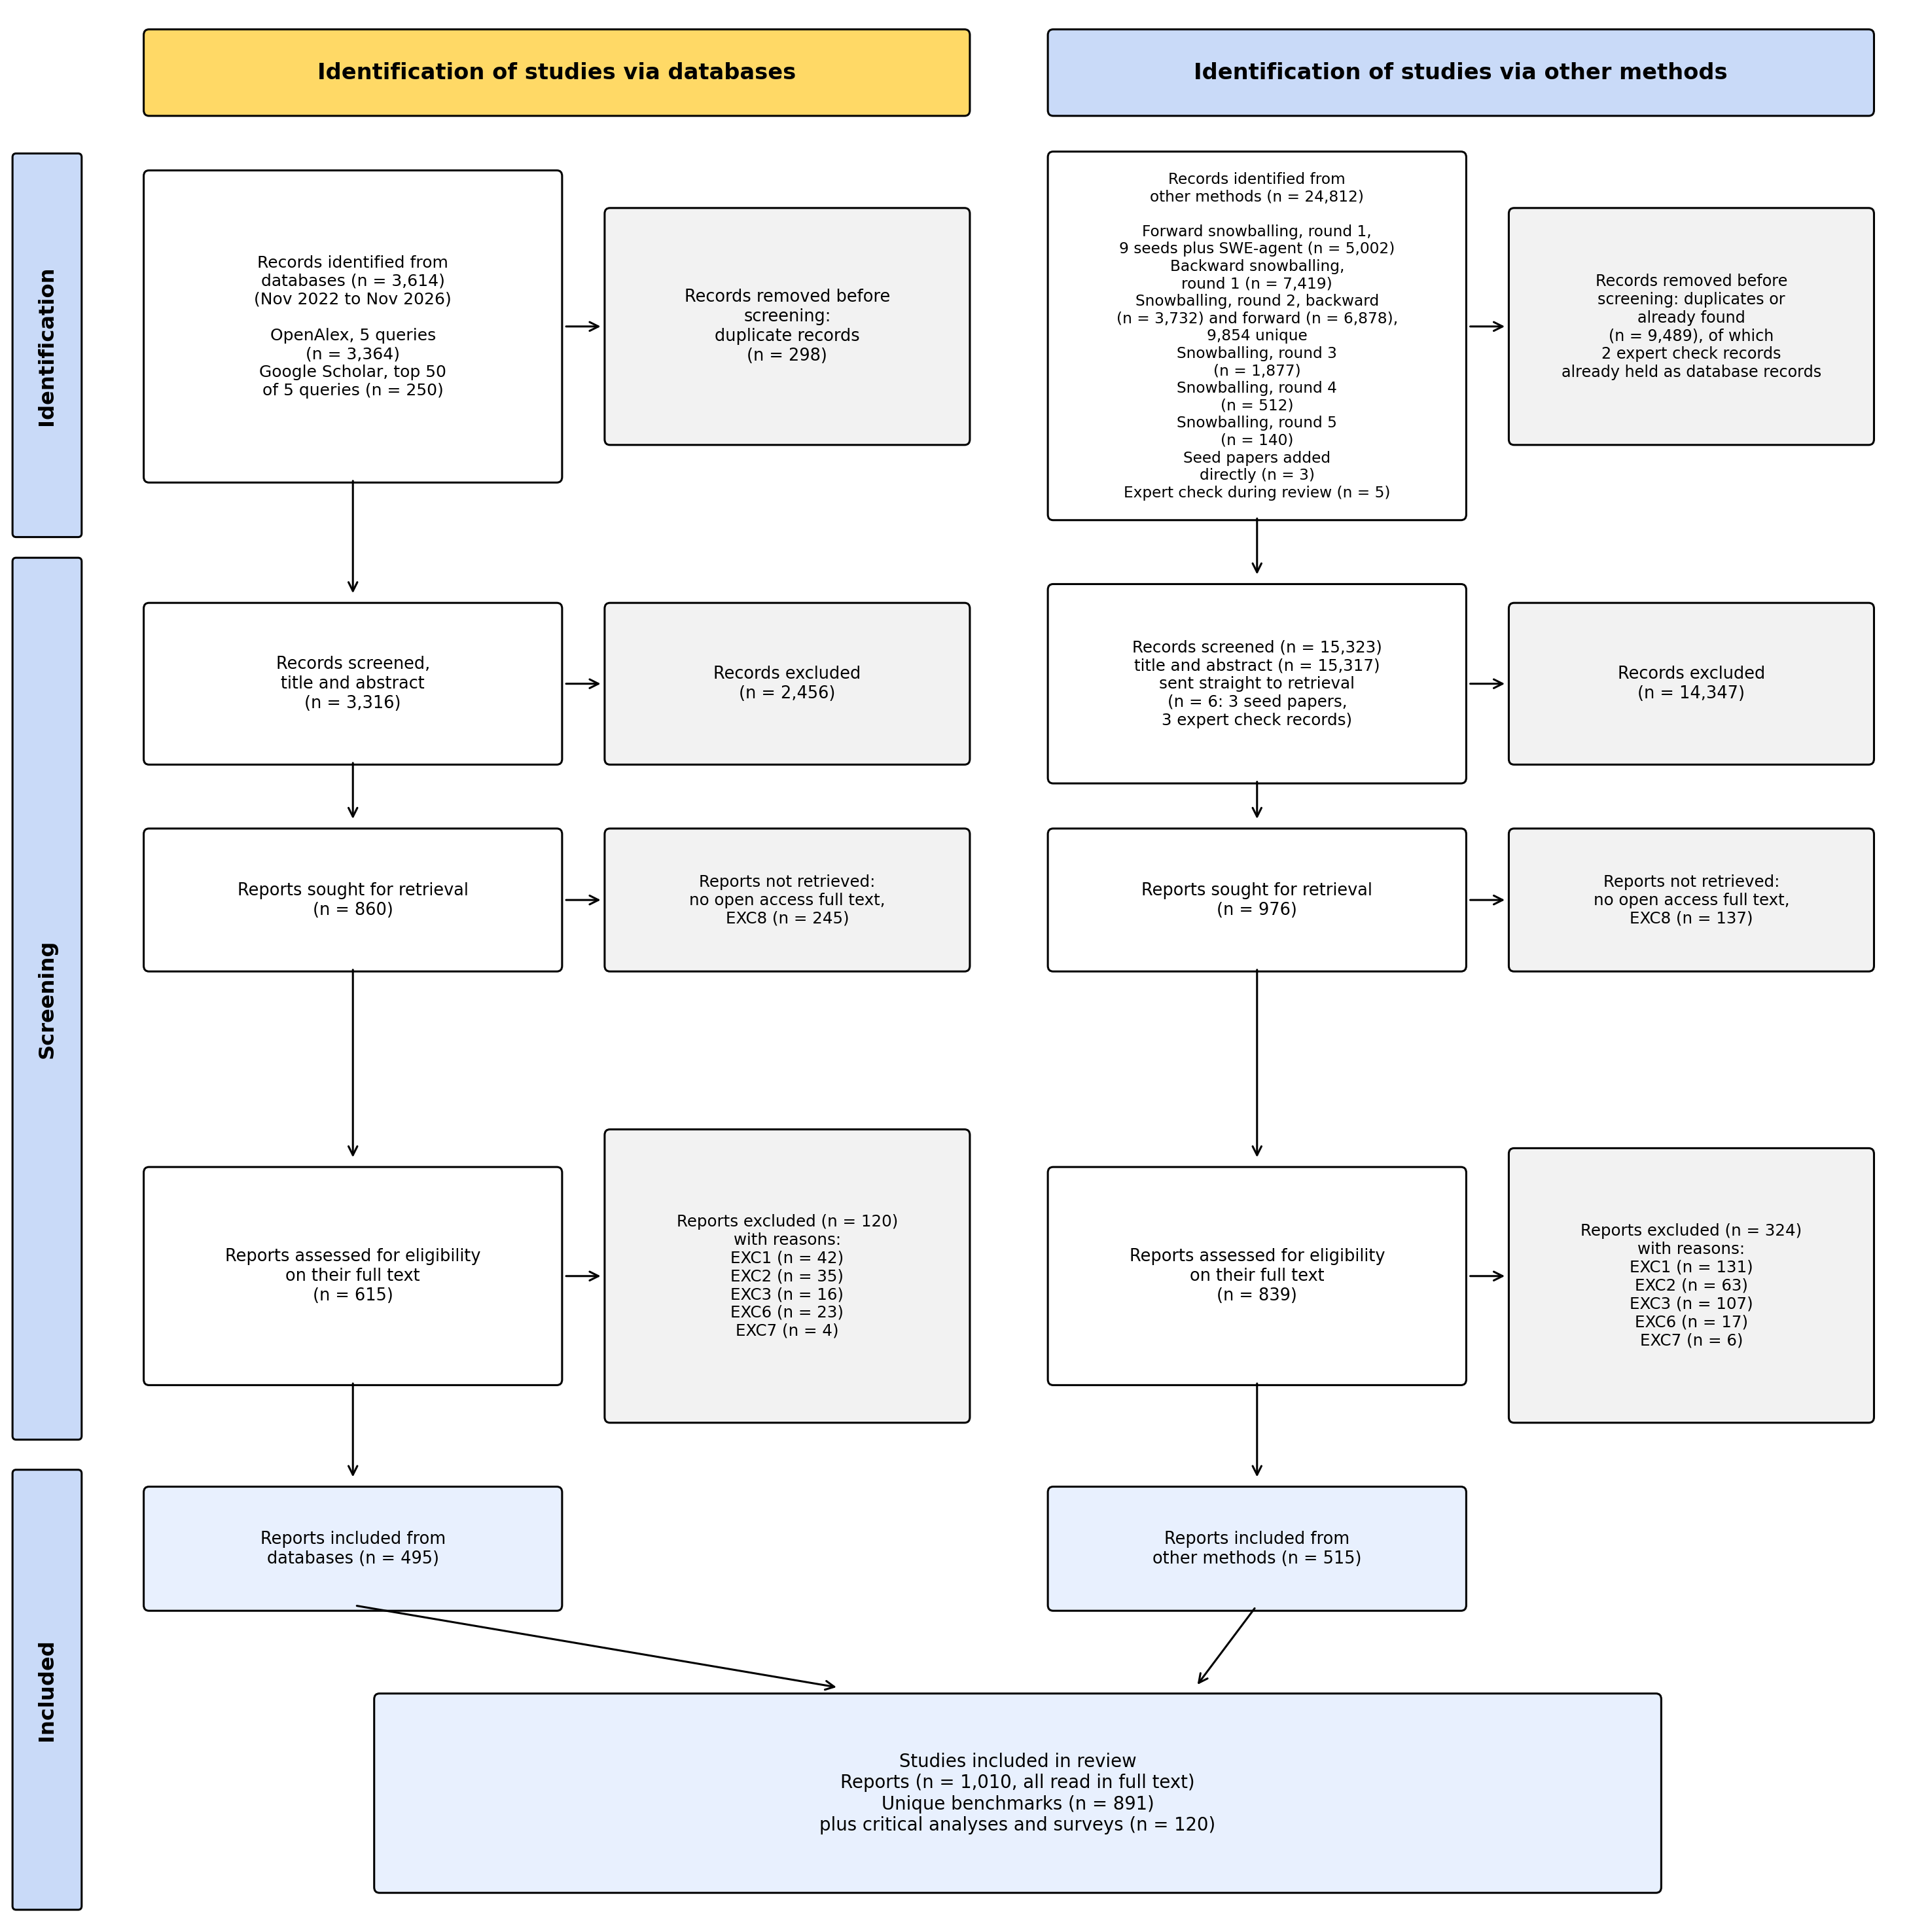

In [5]:
f_ = lambda n: f'{int(n):,}'
db = lambda item: PC[item]['Databases']; ot = lambda item: PC[item]['Other methods']
later = sorted((int(re.search(r'round (\d)', k).group(1)), v['Other methods']) for k, v in PC.items() if re.match(r'Snowballing, round [3-9]$', k))
seeds, xchk, direct = ot('Seed papers added directly'), ot('Expert check during the review'), ot('sent straight to retrieval (seed papers and new expert check records)')
x_old = ot('of which expert check records already held as database records'); x_new = direct - seeds
exc = {arm: {k.strip(): v[arm] for k, v in PC.items() if k.startswith('EXC') and v[arm]} for arm in ('Databases', 'Other methods')}
exl = lambda c: '\n'.join(f'{k} (n = {f_(v)})' for k, v in sorted(c.items(), key=lambda kv: int(re.sub(r'\D', '', kv[0]))))
fig, ax = plt.subplots(figsize=(17, 17.3)); ax.set_xlim(-7, 100); ax.set_ylim(10, 112); ax.axis('off')
def box(x, y, w, h, t, fc='white', fs=8.4):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.3', fc=fc, ec='black', lw=1)); ax.text(x + w / 2, y + h / 2, t, ha='center', va='center', fontsize=fs)
def arr(x1, y1, x2, y2): ax.annotate('', xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle='->', lw=1))
GREY, BLUE = '#f2f2f2', '#e8f0fe'
for x, lab, c in ((1, 'Identification of studies via databases', '#ffd966'), (52, 'Identification of studies via other methods', '#c9daf8')):
    ax.add_patch(FancyBboxPatch((x, 106.5), 46, 4, boxstyle='round,pad=0.3', fc=c, ec='black')); ax.text(x + 23, 108.5, lab, ha='center', va='center', fontsize=11, weight='bold')
for y0, y1, lab in ((84, 104, 'Identification'), (36, 82.5, 'Screening'), (11, 34, 'Included')):
    ax.add_patch(FancyBboxPatch((-6.5, y0), 3.5, y1 - y0, boxstyle='round,pad=0.2', fc='#c9daf8', ec='black'))
    ax.text(-4.75, (y0 + y1) / 2, lab, rotation=90, ha='center', va='center', fontsize=10.5, weight='bold')
LM, LS, RM, RS, MW, SW = 1, 27, 52, 78, 23, 20
box(LM, 87, MW, 16, f"Records identified from\ndatabases (n = {f_(db('Records identified'))})\n(Nov 2022 to Nov 2026)\n\nOpenAlex, 5 queries\n(n = {f_(db('OpenAlex, 5 queries'))})\nGoogle Scholar, top 50\nof 5 queries (n = {f_(db('Google Scholar, top 50 of 5 queries'))})", fs=8.2)
box(LS, 89, SW, 12, f"Records removed before\nscreening:\nduplicate records\n(n = {f_(db('Records removed before screening (duplicates or already found)'))})", fc=GREY)
box(RM, 85, MW, 19, f"Records identified from\nother methods (n = {f_(ot('Records identified'))})\n\nForward snowballing, round 1,\n9 seeds plus SWE-agent (n = {f_(ot('Forward snowballing, round 1, 9 seeds plus SWE-agent'))})\nBackward snowballing,\nround 1 (n = {f_(ot('Backward snowballing, round 1'))})\nSnowballing, round 2, backward\n(n = {f_(ot('Snowballing, round 2, backward'))}) and forward (n = {f_(ot('Snowballing, round 2, forward'))}),\n{f_(ot('Snowballing, round 2, unique records'))} unique\n"
    + ''.join(f'Snowballing, round {k}\n(n = {f_(v)})\n' for k, v in later) + f'Seed papers added\ndirectly (n = {seeds})\nExpert check during review (n = {xchk})', fs=7.6)
box(RS, 89, SW, 12, f"Records removed before\nscreening: duplicates or\nalready found\n(n = {f_(ot('Records removed before screening (duplicates or already found)'))}), of which\n{x_old} expert check records\nalready held as database records", fc=GREY, fs=7.8)
box(LM, 72, MW, 8, f"Records screened,\ntitle and abstract\n(n = {f_(db('Records screened'))})")
box(LS, 72, SW, 8, f"Records excluded\n(n = {f_(db('Records excluded at title and abstract'))})", fc=GREY)
box(RM, 71, MW, 10, f"Records screened (n = {f_(ot('Records screened'))})\ntitle and abstract (n = {f_(ot('screened on title and abstract'))})\nsent straight to retrieval\n(n = {direct}: {seeds} seed papers,\n{x_new} expert check records)", fs=8)
box(RS, 72, SW, 8, f"Records excluded\n(n = {f_(ot('Records excluded at title and abstract'))})", fc=GREY)
for x, xs, a in ((LM, LS, db), (RM, RS, ot)):
    box(x, 61, MW, 7, f"Reports sought for retrieval\n(n = {f_(a('Reports sought for retrieval'))})")
    box(xs, 61, SW, 7, f"Reports not retrieved:\nno open access full text,\nEXC8 (n = {f_(a('Reports not retrieved, no open access full text (EXC8)'))})", fc=GREY, fs=8)
    box(x, 39, MW, 11, f"Reports assessed for eligibility\non their full text\n(n = {f_(a('Reports assessed on their full text'))})")
    box(x, 27, MW, 6, f"Reports included from\n{'databases' if a is db else 'other methods'} (n = {f_(a('Reports included'))})", fc=BLUE)
box(LS, 37, SW, 15, f"Reports excluded (n = {f_(db('Reports excluded on the full text'))})\nwith reasons:\n" + exl(exc['Databases']), fc=GREY, fs=8)
box(RS, 37, SW, 14, f"Reports excluded (n = {f_(ot('Reports excluded on the full text'))})\nwith reasons:\n" + exl(exc['Other methods']), fc=GREY, fs=8)
box(14, 12, 72, 10, f"Studies included in review\nReports (n = {f_(P('Reports included'))}, all read in full text)\nUnique benchmarks (n = {f_(P('Unique benchmarks'))})\nplus critical analyses and surveys (n = {P('Critical analyses and surveys')})", fc=BLUE, fs=9)
for x, ytop, yscr in ((LM + MW / 2, 87, 72), (RM + MW / 2, 85, 71)):
    arr(x, ytop, x, (80 if x < 50 else 81) + 0.6); arr(x, yscr, x, 68.6); arr(x, 61, x, 50.6); arr(x, 39, x, 33.6)
for xm, xs in ((LM + MW, LS), (RM + MW, RS)):
    for y in (95, 76, 64.5, 44.5): arr(xm + 0.3, y, xs - 0.3, y)
arr(LM + MW / 2, 27, 40, 22.6); arr(RM + MW / 2, 27, 60, 22.6)
save(fig, 'Figure_1_PRISMA_flow')
display(Image(str(FIG / 'Figure_1_PRISMA_flow.png'), width=800))

### Figure 2. Benchmarks introduced per year, by top level task category

benchmarks per year: {2022: 1, 2023: 9, 2024: 66, 2025: 161, 2026: 654}


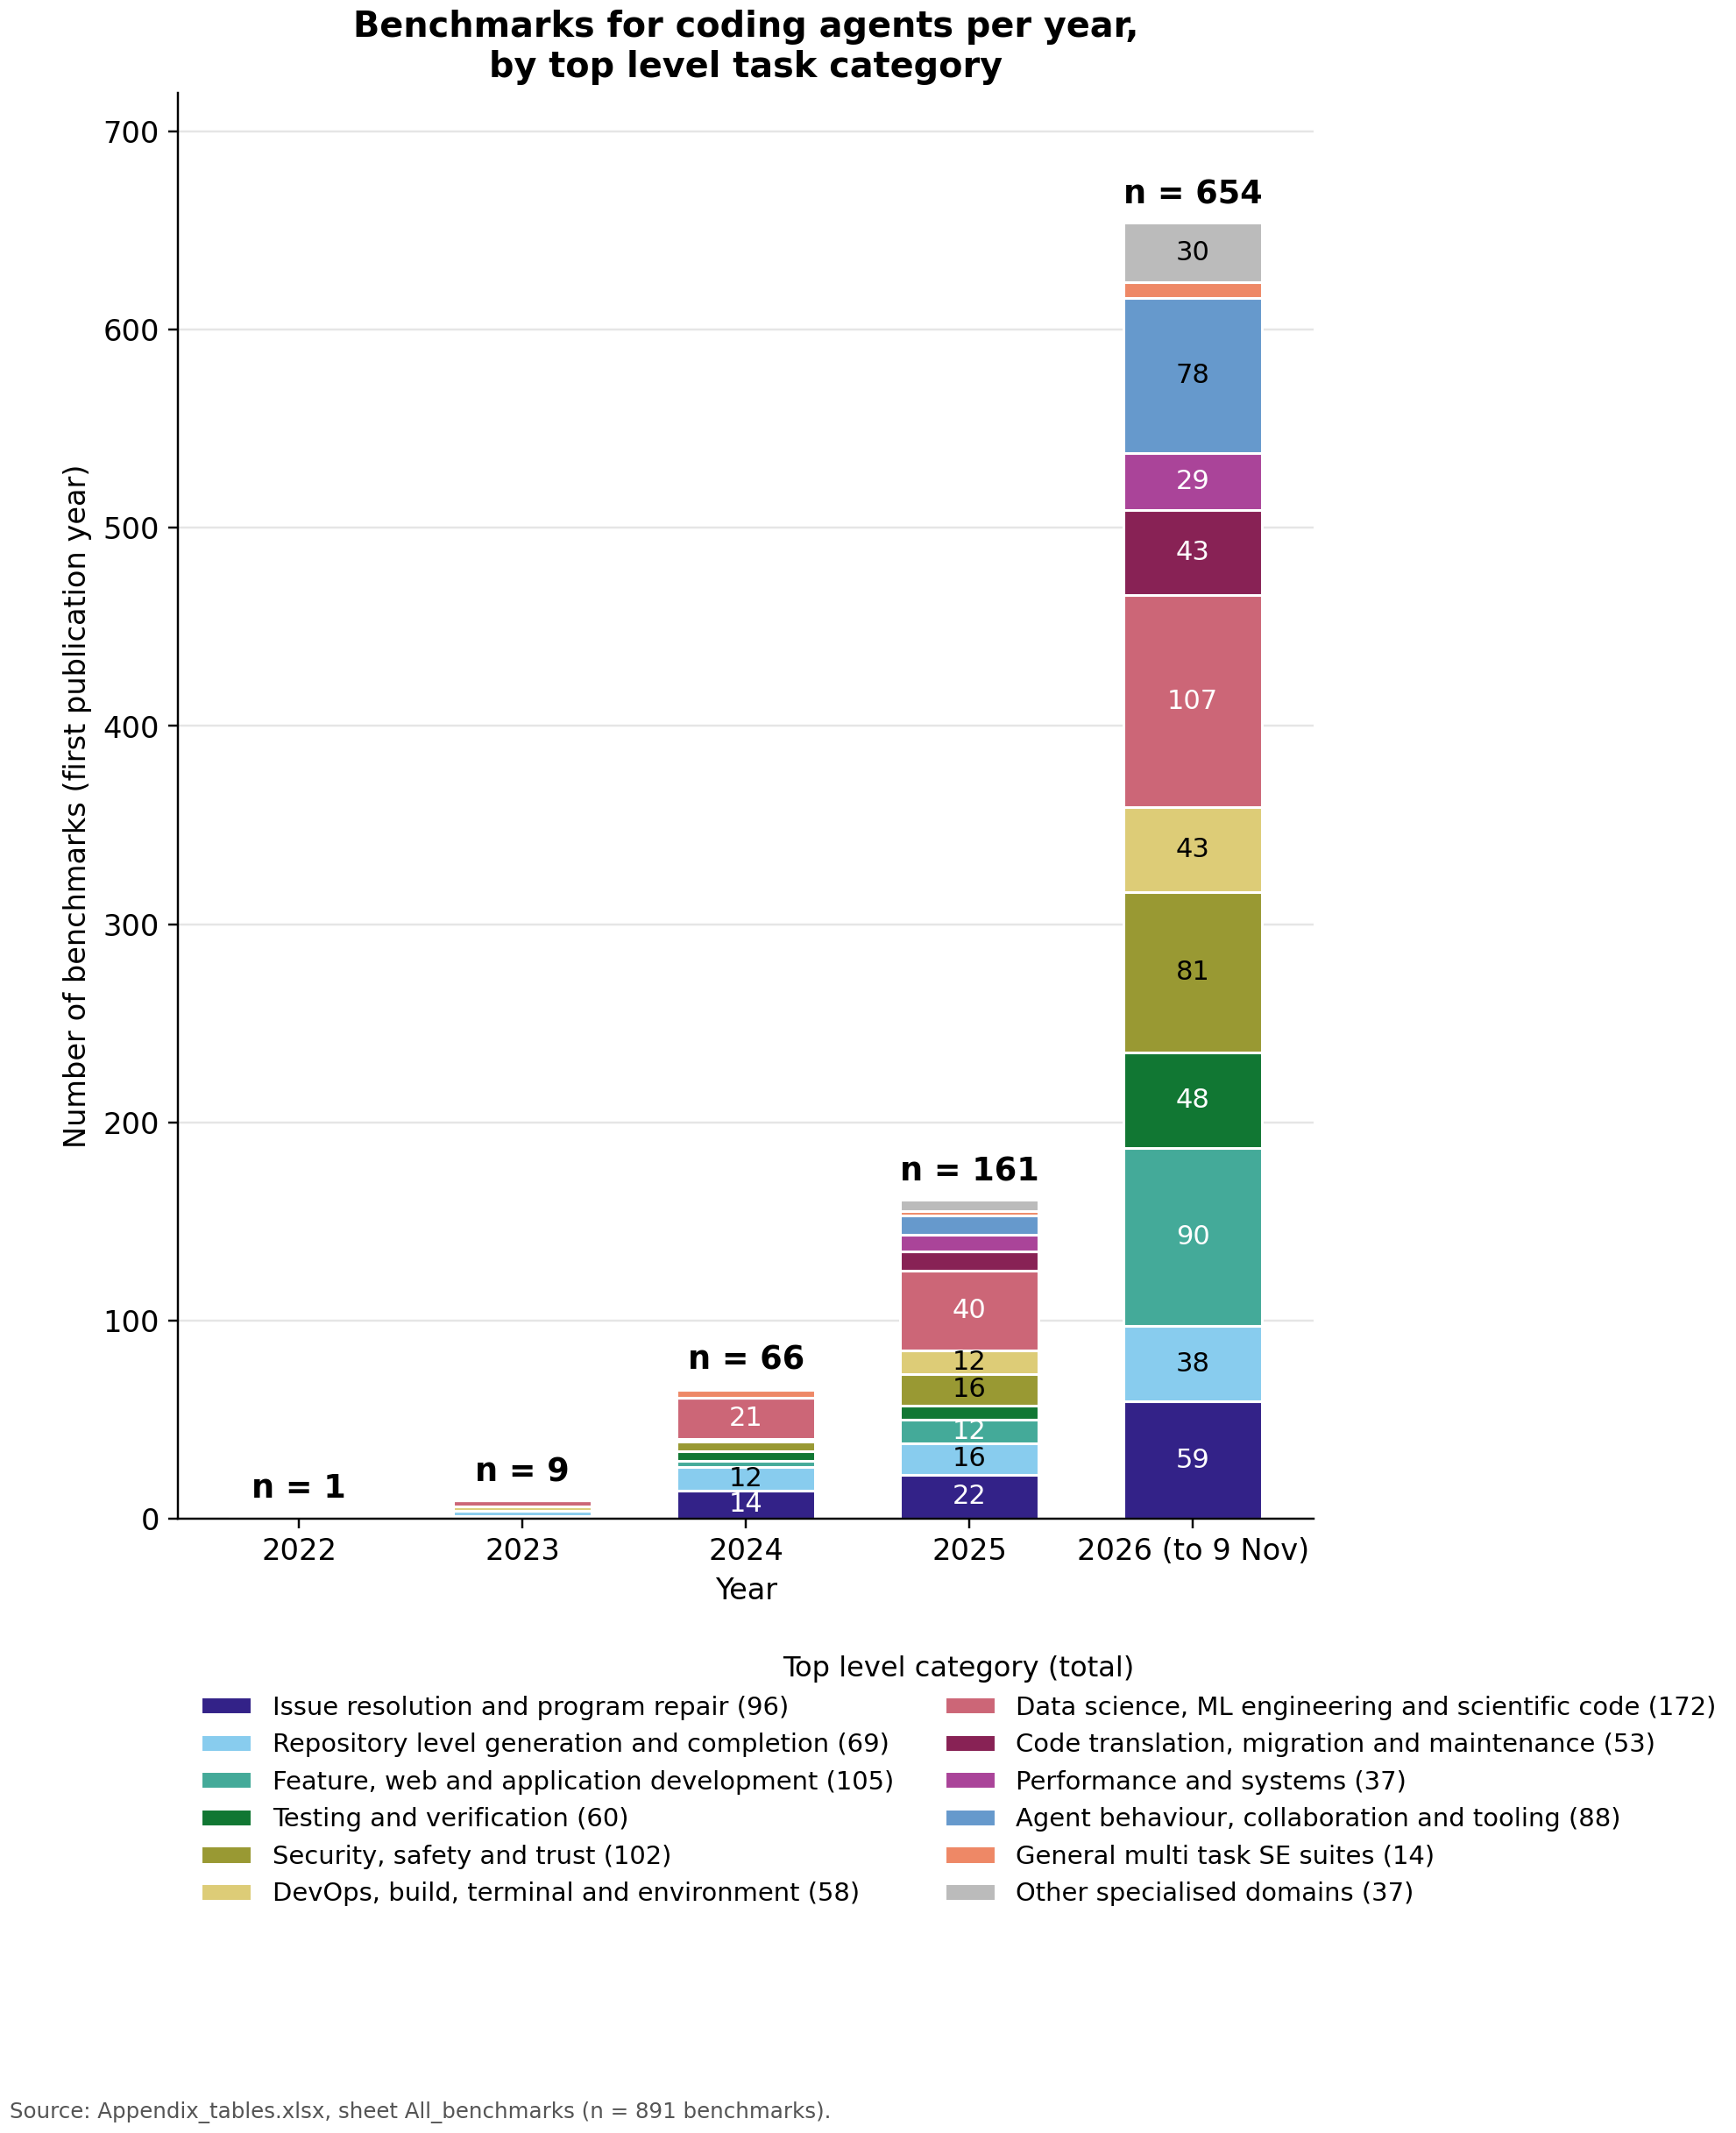

In [6]:
years = sorted({b['Year'] for b in B})
ylab = [str(y) + (' (to 9 Nov)' if y == 2026 else '') for y in years]
cnt = collections.Counter((b['Year'], b['Top level category']) for b in B)
fig, ax = plt.subplots(figsize=(7.6, 9.6)); bottom = [0] * len(years)
for t in TOPS:
    vals = [cnt[(y, t)] for y in years]
    ax.bar(ylab, vals, bottom=bottom, color=COL[t], edgecolor='white', linewidth=1, label='%s (%d)' % (t, sum(vals)), width=0.62)
    for i, v in enumerate(vals):
        if v >= 12: ax.text(i, bottom[i] + v / 2, str(v), ha='center', va='center', fontsize=10, color=ink(COL[t]))
    bottom = [a + b for a, b in zip(bottom, vals)]
for i, tot in enumerate(bottom): ax.text(i, tot + 6, 'n = %d' % tot, ha='center', va='bottom', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of benchmarks (first publication year)'); ax.set_xlabel('Year'); ax.set_ylim(0, max(bottom) * 1.1)
ax.set_title('Benchmarks for coding agents per year,\nby top level task category', fontsize=13)
ax.legend(title='Top level category (total)', fontsize=9.5, title_fontsize=10.5, loc='upper left', frameon=False, bbox_to_anchor=(0.0, -0.08), ncol=2)
ax.yaxis.grid(True, color='#e5e5e5'); ax.set_axisbelow(True); note(fig, -0.205)
save(fig, 'Figure_2_benchmarks_per_year')
print('benchmarks per year:', dict(zip(years, bottom)))
display(Image(str(FIG / 'Figure_2_benchmarks_per_year.png'), width=550))

### Figure 3. The SWE-bench family lineage

Members of the SWE-bench family (column `Family`) are grouped by the kind of derivative they are, using rules on the benchmark
name (first match wins), then by year. Live or rolling benchmarks and non Python issue resolution benchmarks not caught by a name
rule are placed by their coded facets.

SWE-bench family members: 123 | by type: {'Other derivatives (new task types, domains, settings)': 49, 'Subset, verified or audited': 11, 'Harder or professional': 14, 'Live or rolling': 8, 'Multilingual': 26, 'Training data and task generators': 12, 'Multimodal': 2}


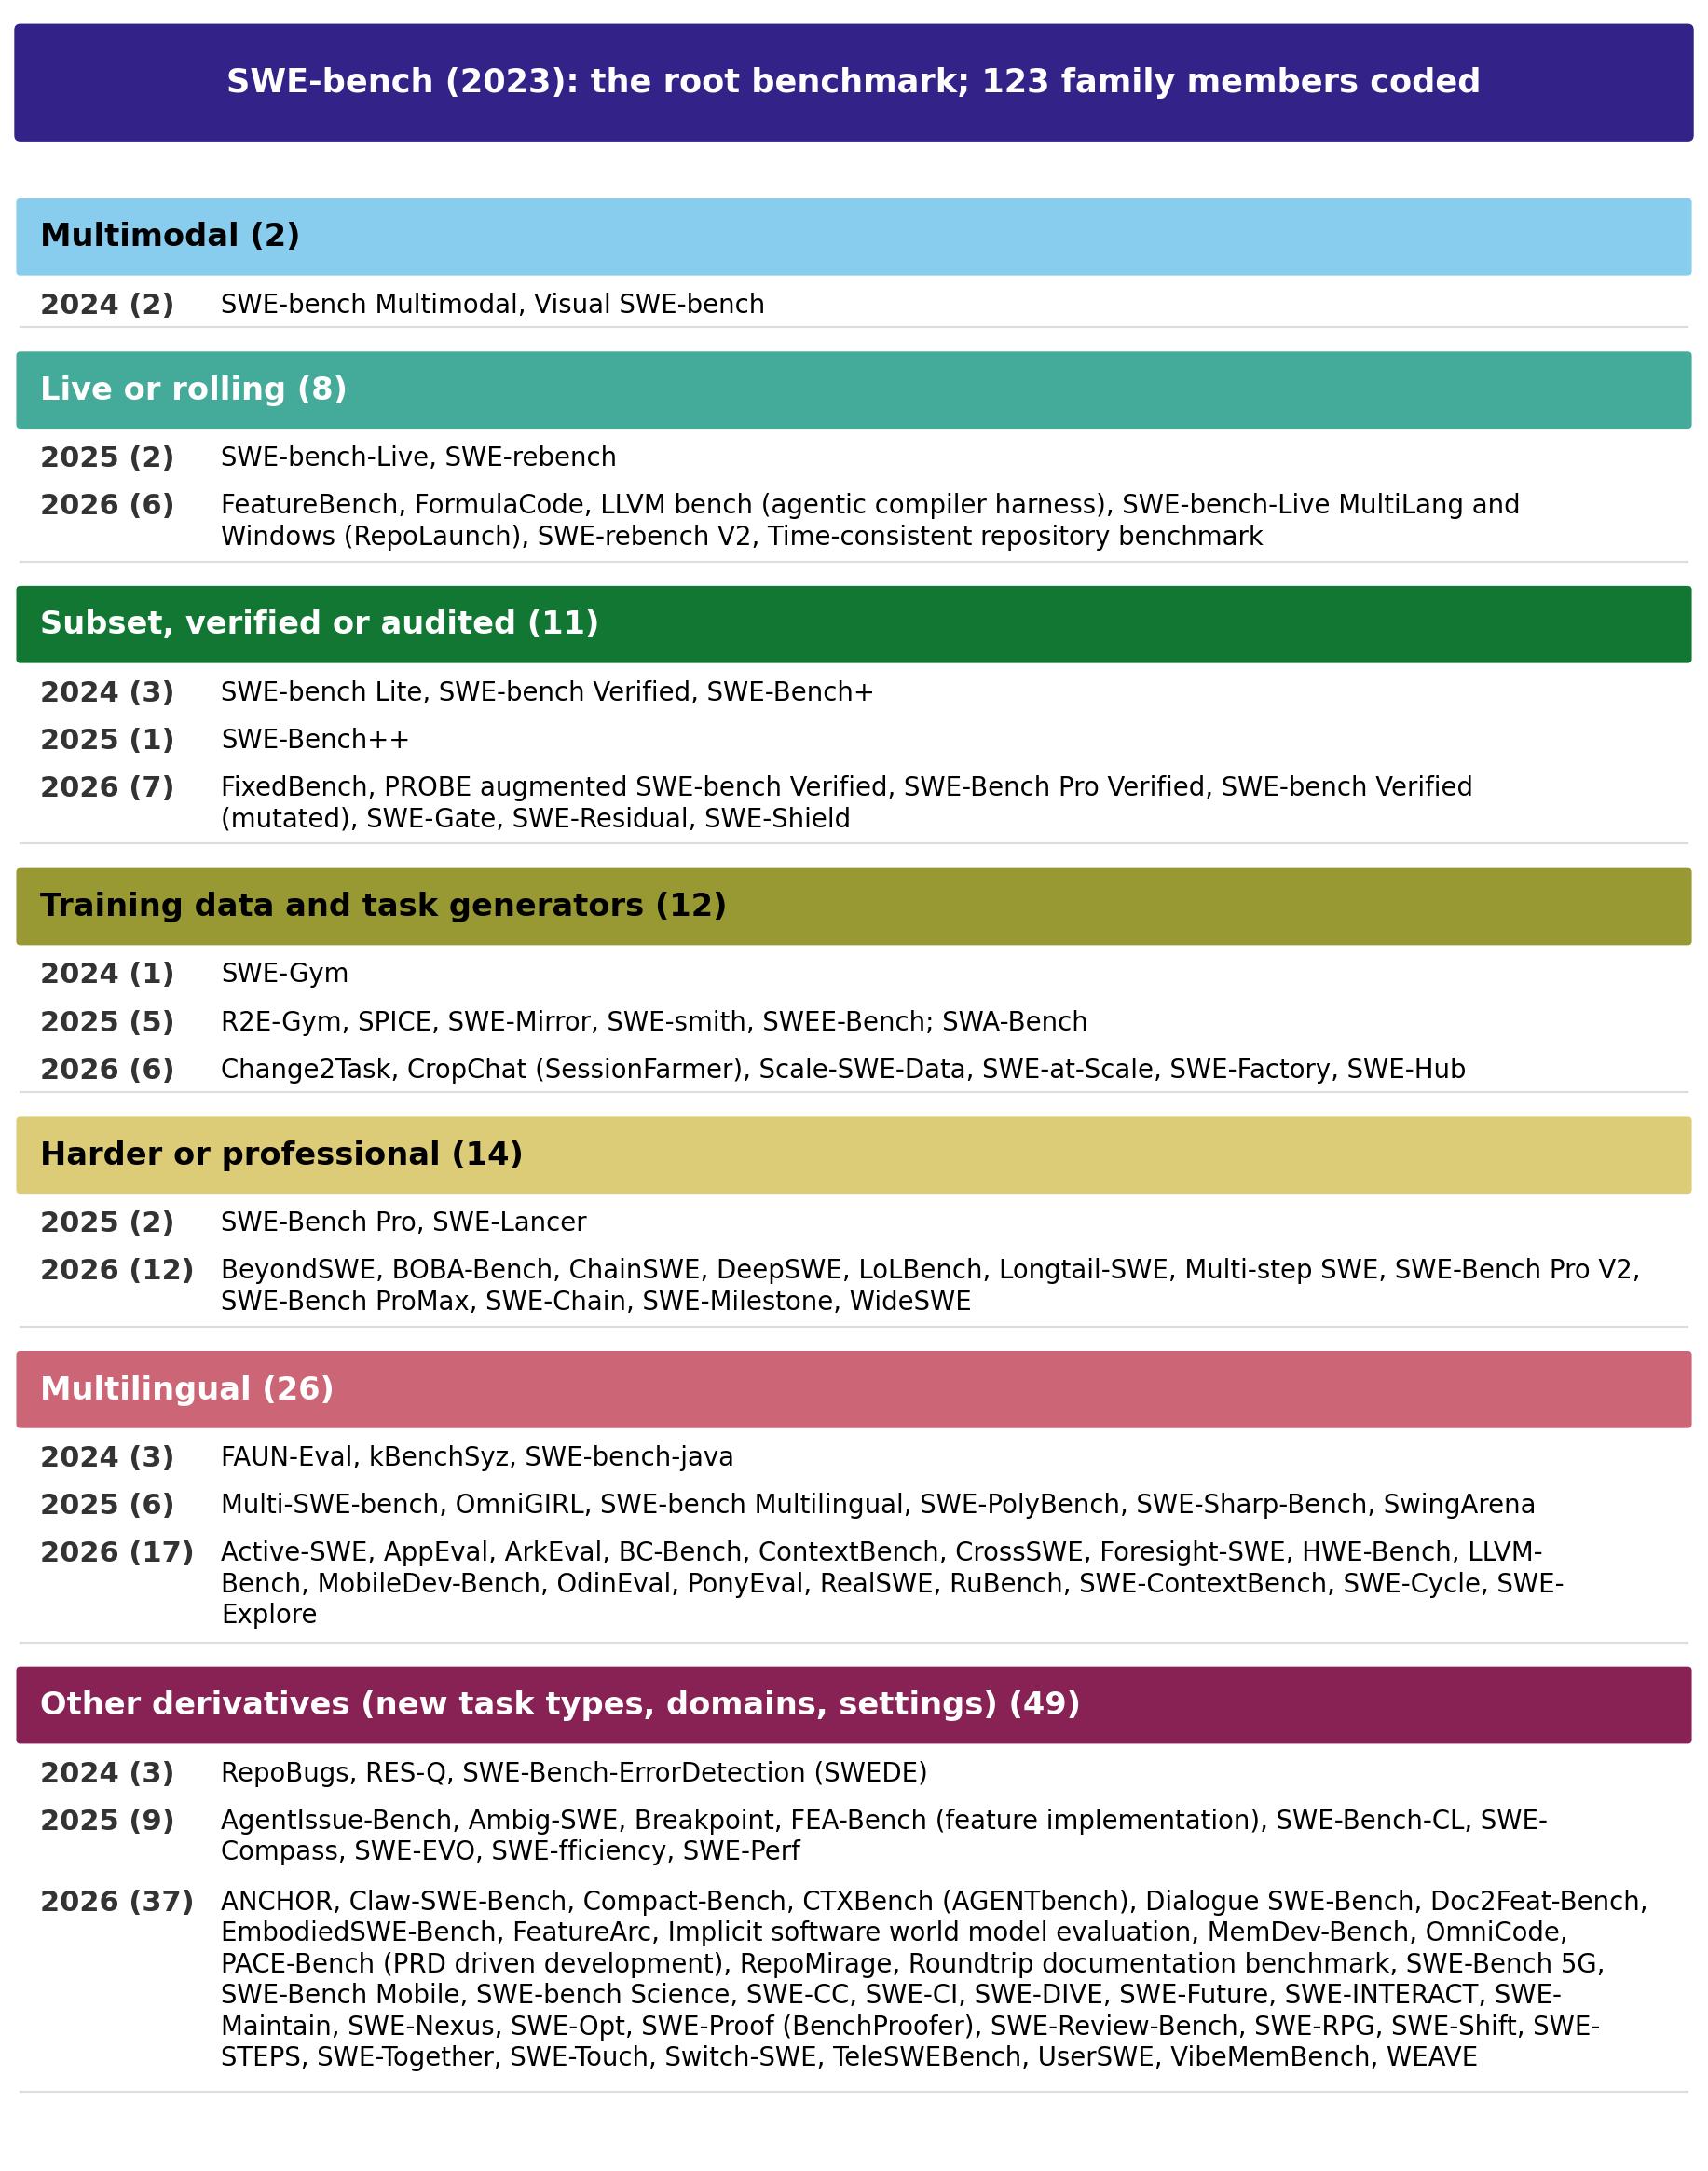

In [7]:
SWE_TYPES = [
 ('Multimodal', r'multimodal|visual|vision|polyvision|image|screenshot'),
 ('Live or rolling', r'live|swe-rebench|rolling|fresh|time.consistent'),
 ('Subset, verified or audited', r'verified|lite|\+$|\+\+|plus|abs\b|mutated|probe|fixed|residual|gate|shield|clean|repaired'),
 ('Training data and task generators', r'gym|smith|factory|universe|hub|next|scale-swe|data|skywork|mirror|openswe|spice|change2task|cropchat|repolaunch|at-scale|swee|swa-bench'),
 ('Harder or professional', r'pro\b|pro |promax|pro v2|complex|lancer|marathon|deep|beyond|wide|milestone|chain|long|lol|multi-step|boba|hard'),
 ('Multilingual', r'java|multi-swe|multilang|omnigirl|rust|sharp|\bru|odin|pony|arkeval|cross|polyglot')]
OTHER = 'Other derivatives (new task types, domains, settings)'
TYPE_ORDER = [t for t, _ in SWE_TYPES] + [OTHER]
fam = [b for b in B if b['Family'] == 'SWE-bench family']
root = [b for b in fam if b['Benchmark'].strip().lower() == 'swe-bench']
rest = [b for b in fam if b not in root]
def swe_type(b):
    n = b['Benchmark'].lower()
    for t, p in SWE_TYPES:
        if re.search(p, n): return t
    if b['flags']['live_updates']: return 'Live or rolling'
    if b['flags']['non_python_languages'] and b['Top level category'] == 'Issue resolution and program repair': return 'Multilingual'
    return OTHER
groups = collections.defaultdict(list)
for b in rest: groups[(swe_type(b), b['Year'])].append(b['Benchmark'])
tcount = collections.Counter(swe_type(b) for b in rest); fyears = sorted({b['Year'] for b in rest})
blocks = []
for t in TYPE_ORDER:
    rows_t = [(y, len(groups[(t, y)]), textwrap.wrap(', '.join(sorted(groups[(t, y)], key=str.lower)), 100)) for y in fyears if groups.get((t, y))]
    blocks.append((t, rows_t))
LH = 0.165
H = 1.0 + sum(0.42 + sum(0.07 + LH * len(r[2]) for r in rows_t) + 0.1 for _, rows_t in blocks) + 0.15
fig, ax = plt.subplots(figsize=(8.4, H)); fig.subplots_adjust(left=0.01, right=0.99, top=0.995, bottom=0.005)
ax.set_xlim(0, 8.4); ax.set_ylim(-H, 0); ax.axis('off')
ax.add_patch(FancyBboxPatch((0.05, -0.62), 8.3, 0.52, boxstyle='round,pad=0.03', fc='#332288', ec='none'))
ax.text(4.2, -0.36, 'SWE-bench (%s): the root benchmark; %d family members coded' % (', '.join(str(b['Year']) for b in root), len(fam)),
        ha='center', va='center', color='white', fontsize=11.5, fontweight='bold')
yy = -0.95
for j, (t, rows_t) in enumerate(blocks):
    c = PAL[(j + 1) % len(PAL)]
    ax.add_patch(FancyBboxPatch((0.05, yy - 0.34), 8.3, 0.34, boxstyle='round,pad=0.02', fc=c, ec='none'))
    ax.text(0.15, yy - 0.17, '%s (%d)' % (t, tcount[t]), va='center', fontsize=11, fontweight='bold', color=ink(c)); yy -= 0.42
    for y, n_, ls in rows_t:
        ax.text(0.15, yy - 0.02, '%d (%d)' % (y, n_), fontsize=10, fontweight='bold', va='top', color='#333333')
        ax.text(1.05, yy - 0.02, '\n'.join(ls), fontsize=9, va='top', linespacing=1.25); yy -= 0.07 + LH * len(ls)
    ax.plot([0.05, 8.35], [yy + 0.04, yy + 0.04], color='#dddddd', lw=0.7); yy -= 0.1
save(fig, 'Figure_3_SWE-bench_family_lineage')
print('SWE-bench family members:', len(fam), '| by type:', dict(tcount))
display(Image(str(FIG / 'Figure_3_SWE-bench_family_lineage.png'), width=600))

### Figure 4. Task taxonomy

Read from the `Taxonomy_subcategories` sheet; the top level counts are the sums of their sub categories.

PASS top level counts from the taxonomy sheet equal the counts in All_benchmarks


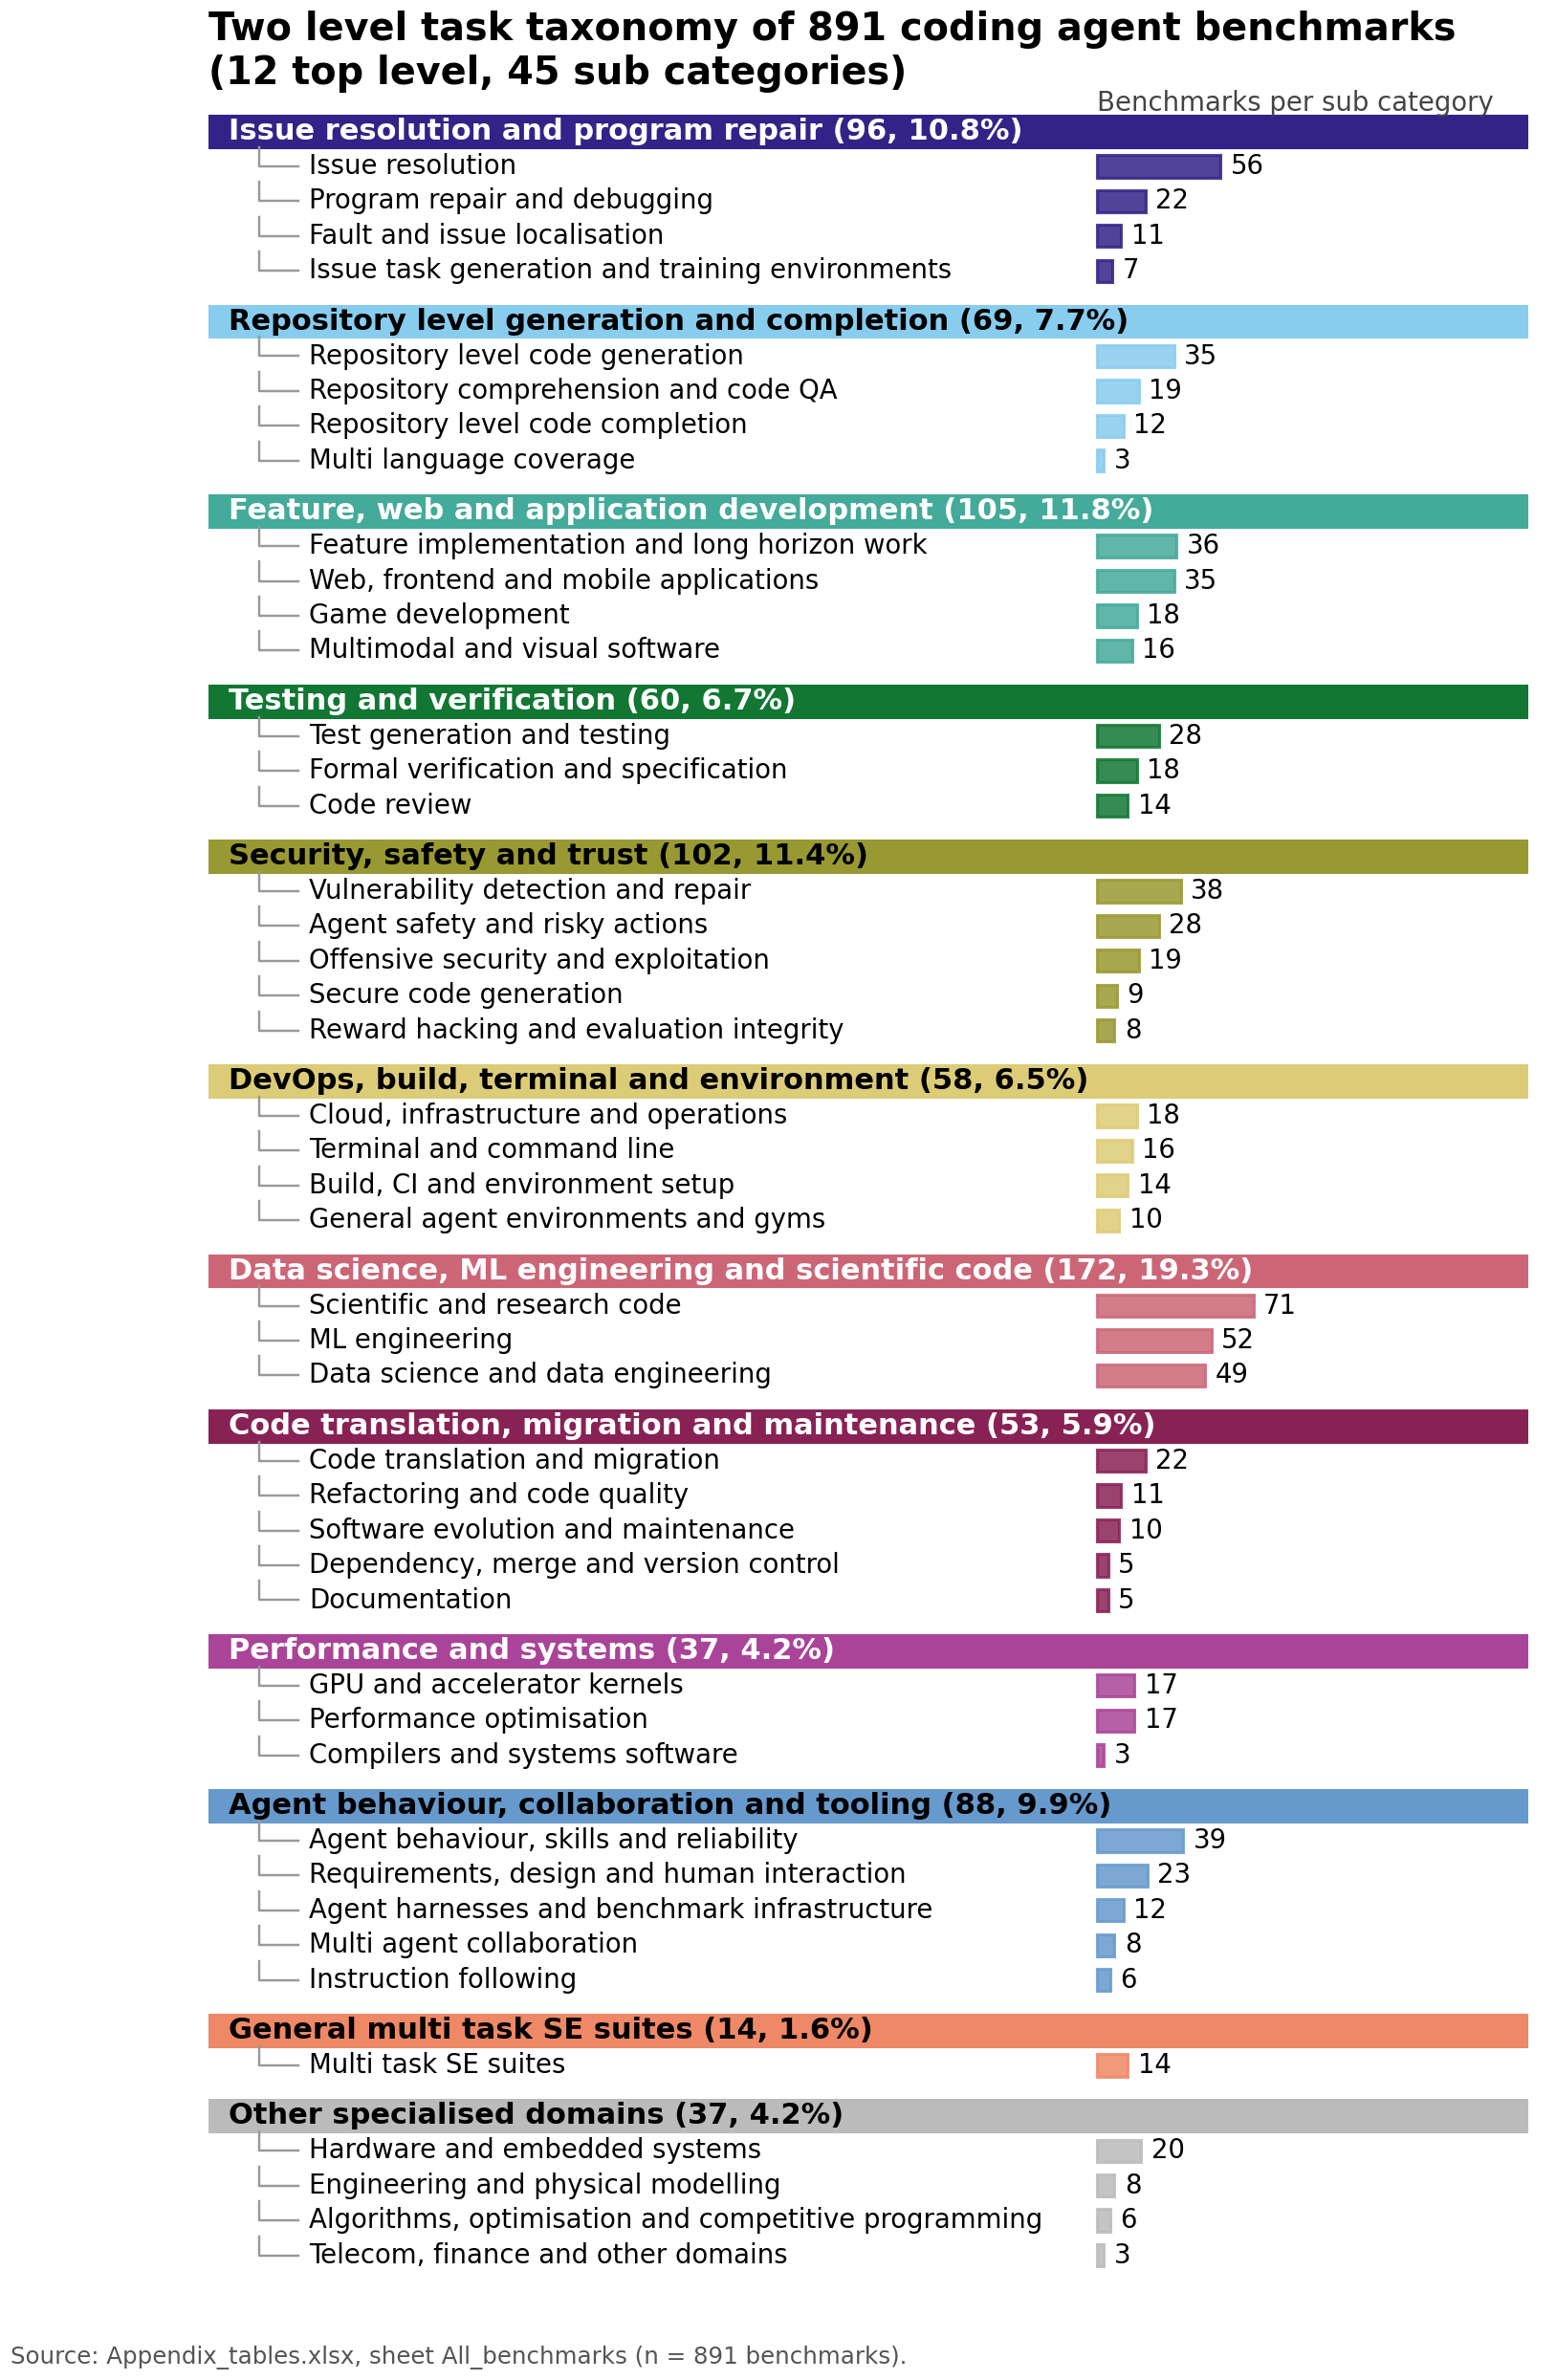

In [8]:
CNT = next(k for k in TAXO[0] if k.startswith('Benchmarks'))
subs = collections.defaultdict(list)
for t in TAXO: subs[t['Top level category']].append((t['Sub category'], int(t[CNT])))
rows = []
for top in TOPS:
    rows.append(('top', top, sum(c for _, c in subs[top])))
    for s, c in sorted(subs[top], key=lambda x: -x[1]): rows.append(('sub', s, c, top))
ntop = len(TOPS)
fig, ax = plt.subplots(figsize=(8.2, 0.165 * (len(rows) + 0.45 * ntop) + 0.7)); fig.subplots_adjust(bottom=0.03, top=0.97)
mx = max(r[2] for r in rows); y = 0
for r in rows:
    if r[0] == 'top':
        y += 0.45; ax.add_patch(Rectangle((0, -y - 0.45), 6.6, 0.9, color=COL[r[1]]))
        ax.text(0.1, -y, '%s (%d, %.1f%%)' % (r[1], r[2], 100.0 * r[2] / N), va='center', fontsize=10, fontweight='bold', color=ink(COL[r[1]])); cur = r[1]
    else:
        ax.plot([0.25, 0.25, 0.45], [-y + 0.55, -y, -y], color='#999999', lw=0.8); ax.text(0.5, -y, r[1], va='center', fontsize=9)
        w = 1.9 * r[2] / mx; ax.add_patch(Rectangle((4.45, -y - 0.32), w, 0.64, color=COL[cur], alpha=0.85)); ax.text(4.45 + w + 0.05, -y, str(r[2]), va='center', fontsize=9)
    y += 1
ax.set_xlim(0, 6.7); ax.set_ylim(-y + 0.4, 0.4); ax.axis('off')
ax.text(4.45, 0.15, 'Benchmarks per sub category', fontsize=9, color='#444444')
ax.set_title('Two level task taxonomy of %d coding agent benchmarks\n(%d top level, %d sub categories)' % (N, ntop, len(TAXO)), loc='left', fontsize=13)
note(fig, 0.0); save(fig, 'Figure_4_taxonomy')
check('top level counts from the taxonomy sheet equal the counts in All_benchmarks',
      all(r[2] == sum(b['Top level category'] == r[1] for b in B) for r in rows if r[0] == 'top'))
display(Image(str(FIG / 'Figure_4_taxonomy.png'), width=600))

### Figures 5 to 8. One figure for each coded facet, in the section of its question

Each figure counts the evaluation benchmarks only (training resources are left out), so its numbers match the table of the same
facet in the report. Facets with several values per benchmark can sum to more than 100 percent.
Figure 5 granularity (RQ2), Figure 6 contamination defences (RQ3), Figure 7 construction (RQ4), Figure 8 limitations (RQ5).

Granularity | Repository 394; Project or system 335; File 89; Function 61
Contamination defence (strict) | None reported 577; Decontamination or memorisation check 99; Time cutoff 72; Task rewriting or mutation 67; Private or held out test set 58; New or synthetic tasks (contamination motivated) 45; Live or rolling updates 33; Other training exposure reduction 23; Canary strings 17; Other (unspecified) 3
Task source | Open source repositories 331; Human written 313; LLM generated 214; Existing benchmarks 197; Other 168; GitHub issues or pull requests 143; Industry or freelance work 36; Competitions 29
Test source | Execution based checker 521; Existing repository tests 256; Human or LLM judge 239; Human written 178; LLM generated 134; No executable tests (reference match) 89; Observational outcome 5; Other 2
Validation | Execution validated 557; Human verified 514; None reported 121
Environment | Docker or sandbox 562; Other or not stated 276; No execution environment 41
Limitations | 

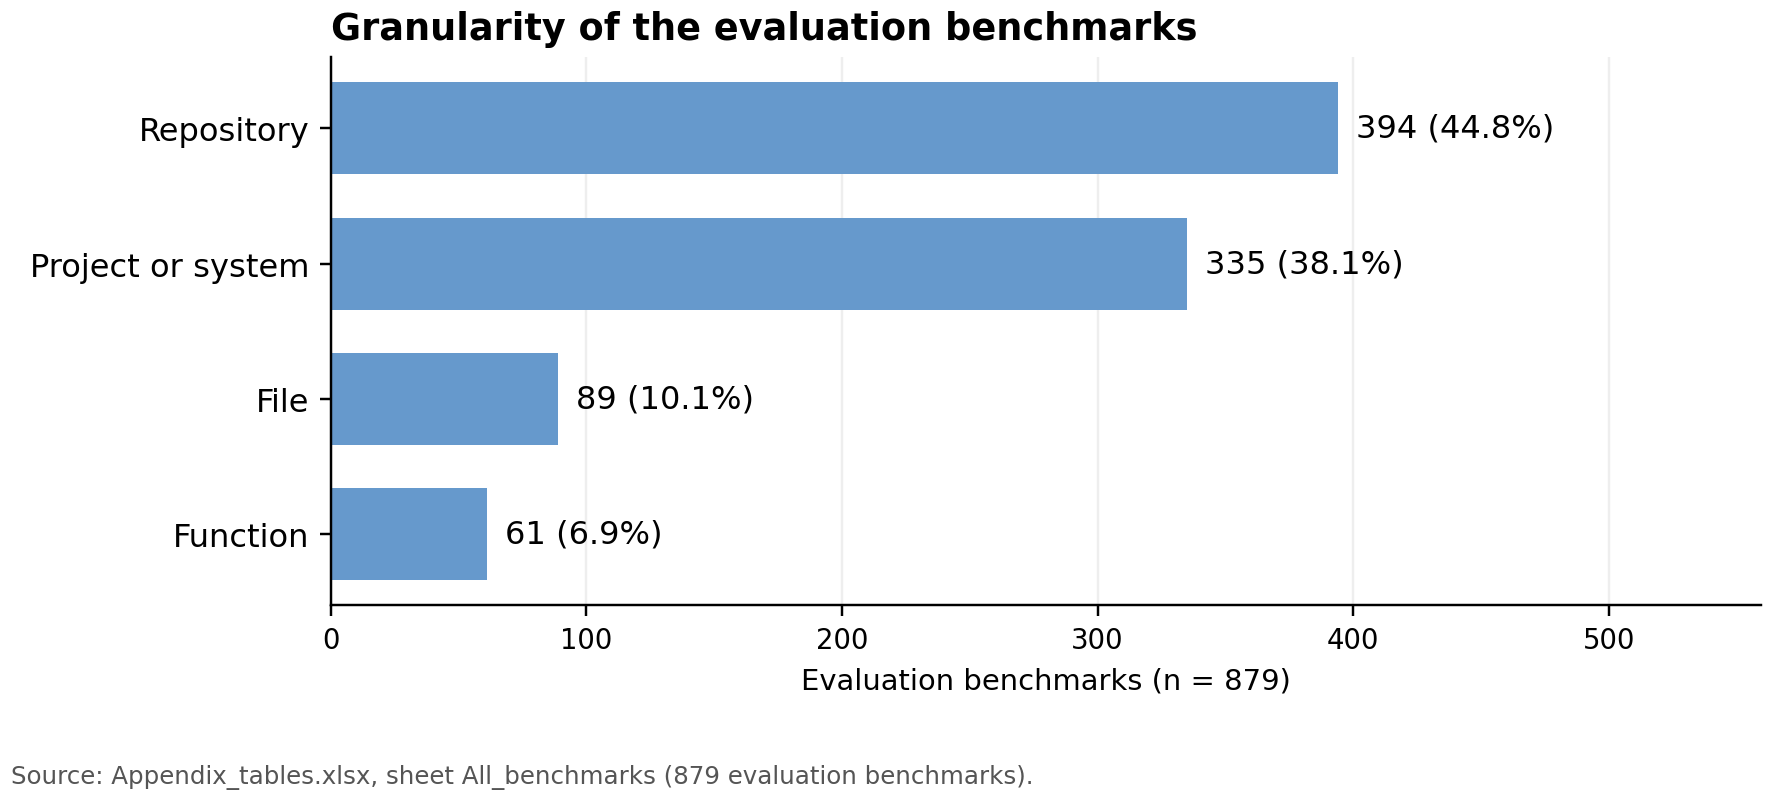

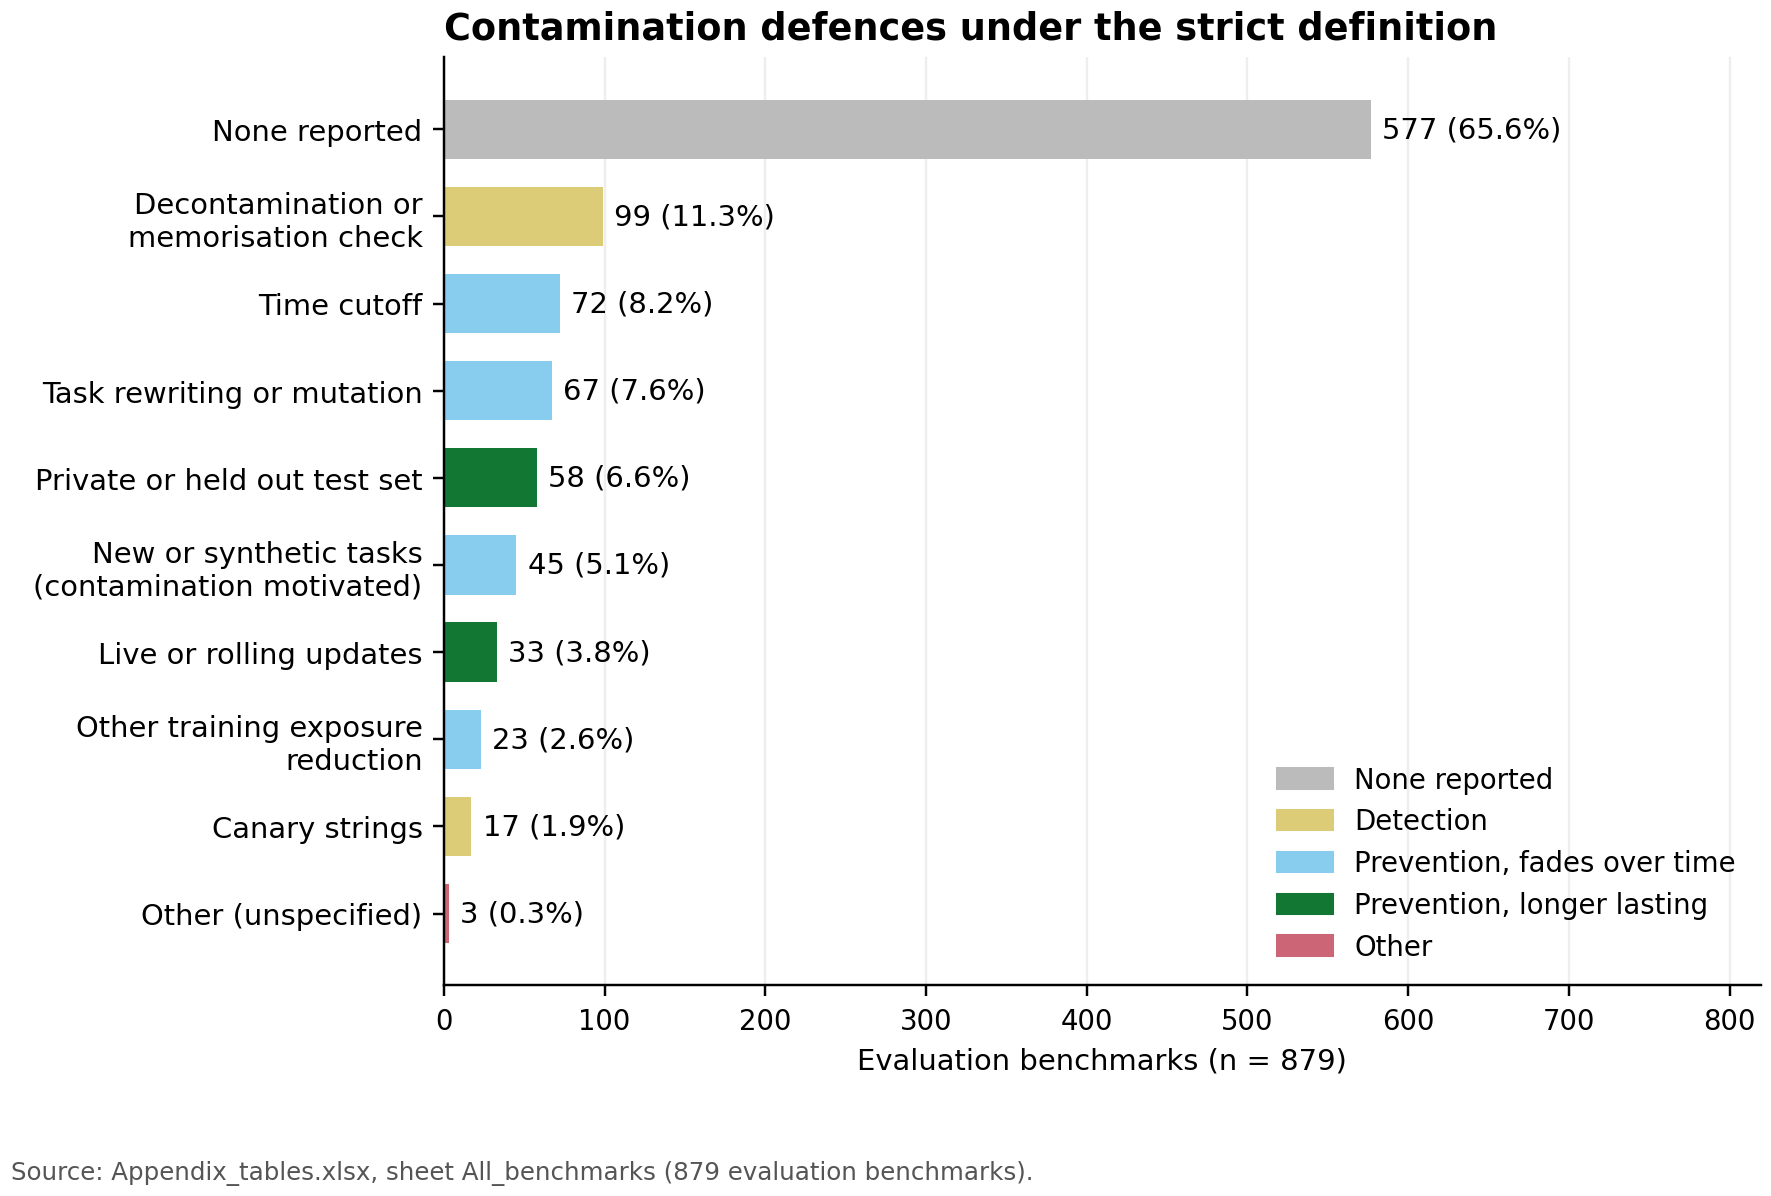

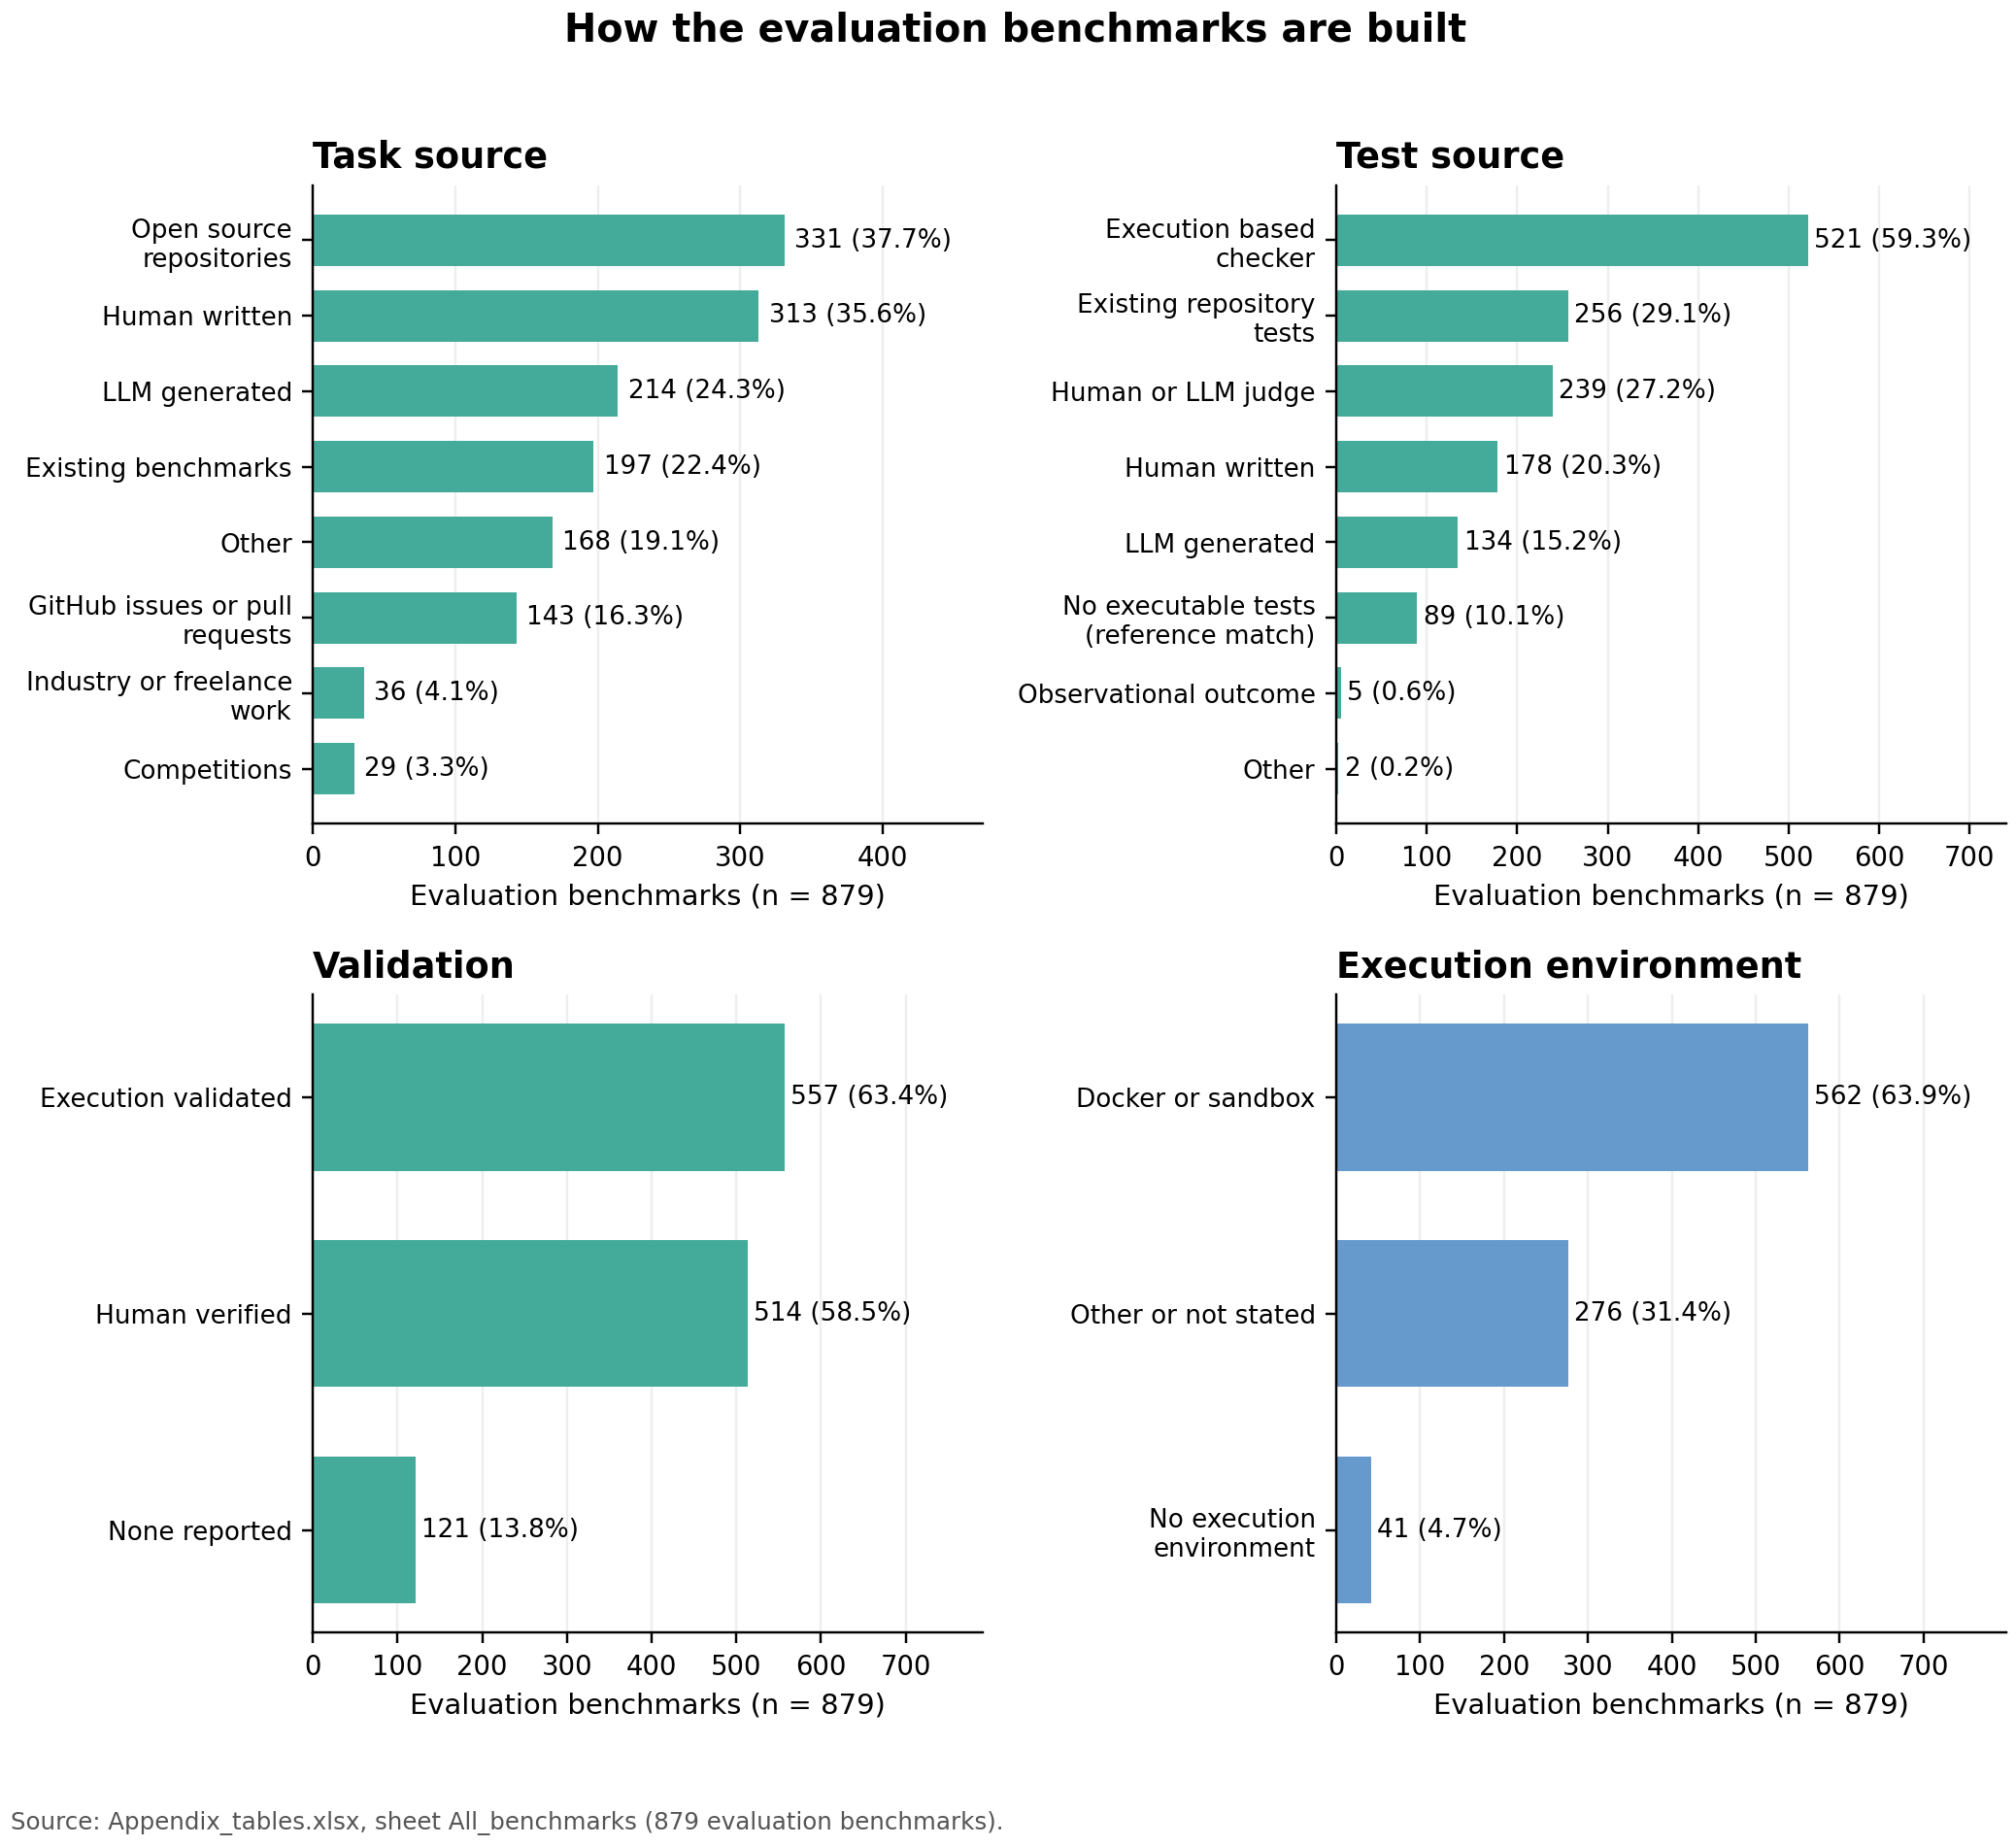

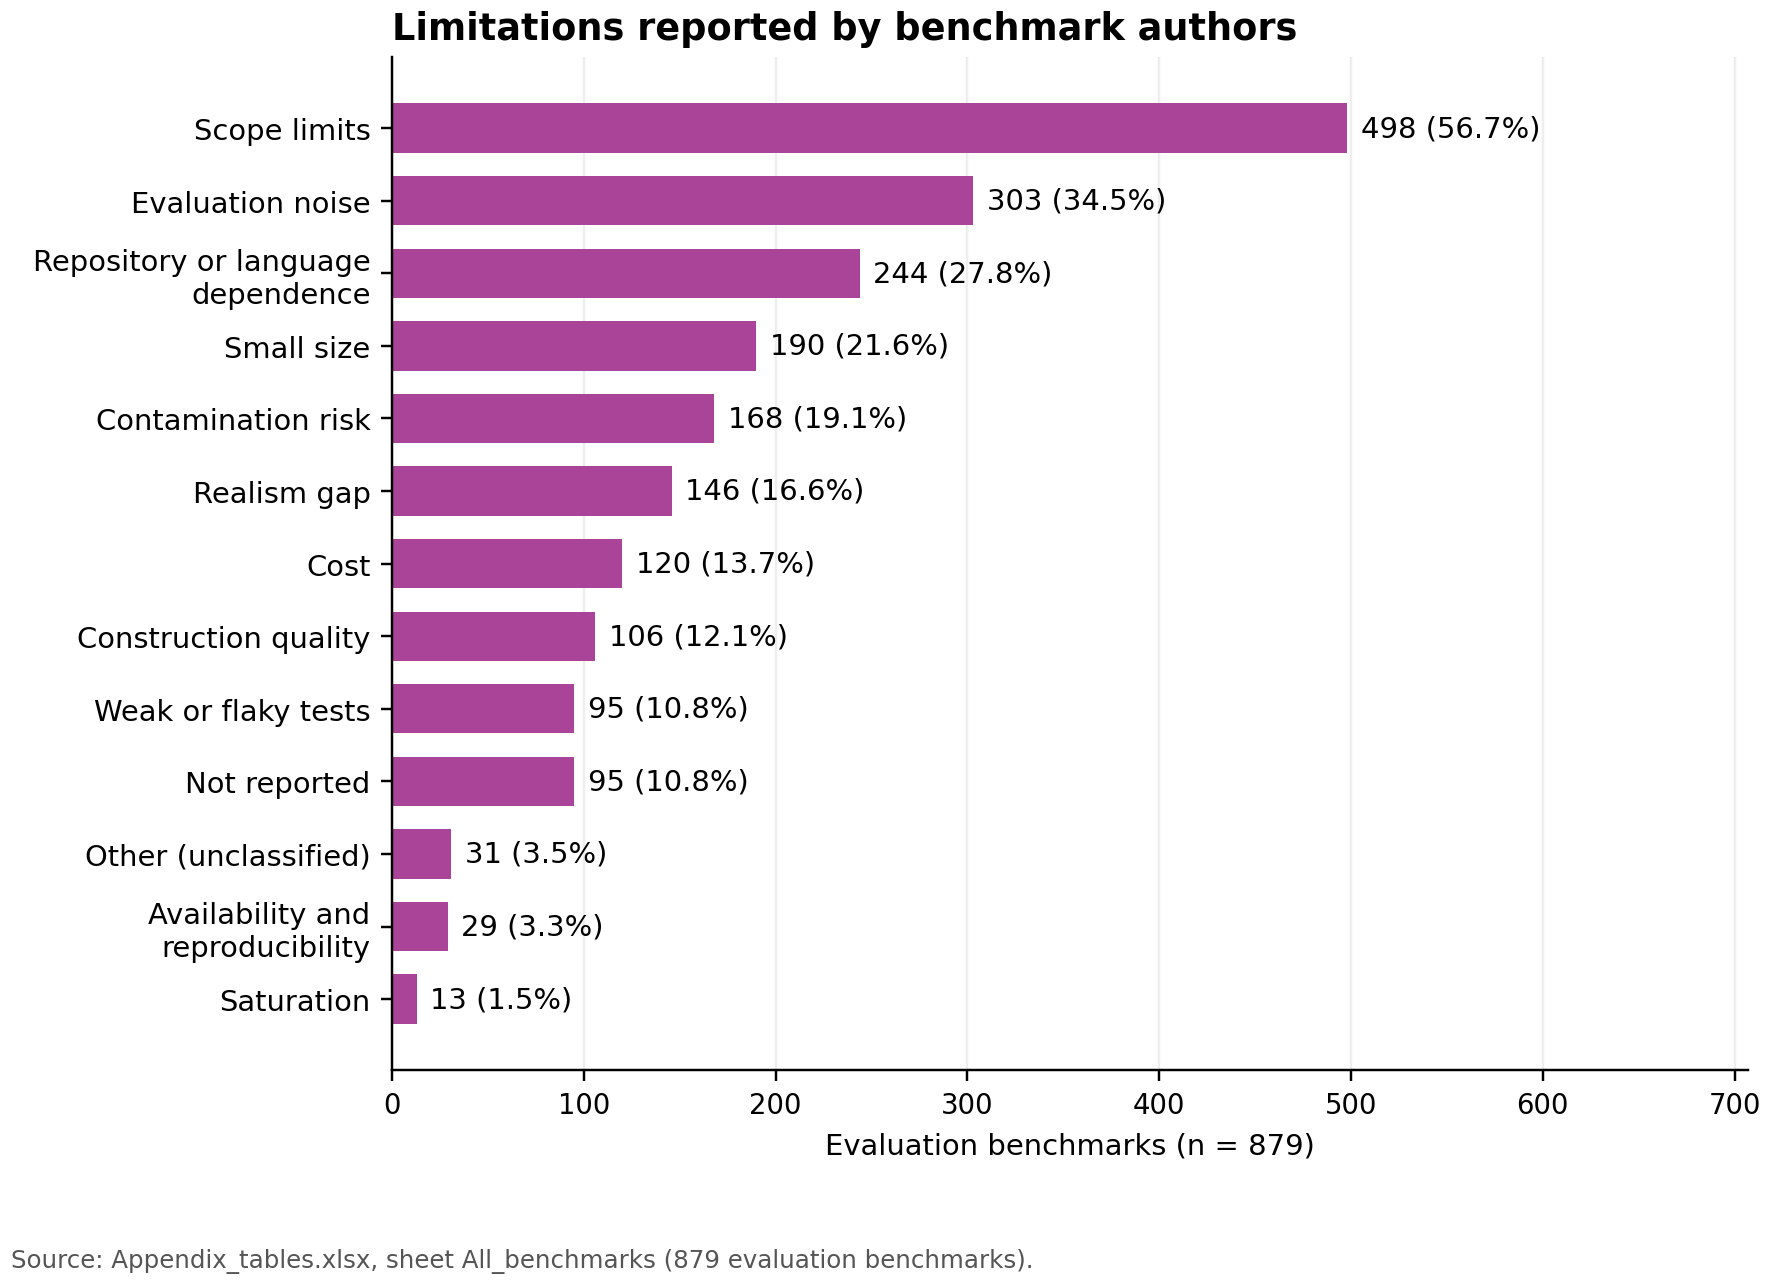

In [9]:
NE = len(EVAL)
SRCE = f'Source: Appendix_tables.xlsx, sheet All_benchmarks ({NE} evaluation benchmarks).'
def note_e(fig, y=0.0):
    fig.text(0.01, y, '\n'.join(textwrap.wrap(SRCE, 110)), fontsize=8, color='#555555', ha='left', va='top')
def counts(k):   # most common first; at a tie, values such as None reported, Not reported or Other come after the real ones (as in the tables)
    c = collections.Counter(x for b in EVAL for x in (b[k] if k in MULTI else [b[k]]))
    return sorted(c.items(), key=lambda kv: (-kv[1], kv[0].lower().startswith(('none reported', 'not reported', 'other'))))
def bars(ax, items, colors, title, wrap=30, fs=9.5):
    labs = ['\n'.join(textwrap.wrap(a, wrap)) for a, _ in items][::-1]; vals = [v for _, v in items][::-1]
    ax.barh(labs, vals, color=colors[::-1] if isinstance(colors, list) else colors, height=0.68)
    for i, v in enumerate(vals): ax.text(v + NE * 0.008, i, '%d (%.1f%%)' % (v, 100.0 * v / NE), va='center', fontsize=fs)
    ax.set_xlim(0, max(vals) * 1.42); ax.set_title(title, fontsize=12, loc='left')
    ax.set_xlabel('Evaluation benchmarks (n = %d)' % NE, fontsize=9.5); ax.tick_params(axis='y', labelsize=fs); ax.tick_params(axis='x', labelsize=9)
    ax.xaxis.grid(True, color='#eeeeee'); ax.set_axisbelow(True)
FSUM = {}

# Figure 5. Granularity (RQ2)
items = counts('Granularity'); FSUM['Granularity'] = dict(items)
fig, ax = plt.subplots(figsize=(8.2, 3.6))
bars(ax, items, '#6699CC', 'Granularity of the evaluation benchmarks', fs=10.5)
fig.tight_layout(rect=(0, 0.04, 1, 1)); note_e(fig); save(fig, 'Figure_5_granularity')

# Figure 6. Contamination defences (RQ3), coloured by kind of defence
KIND = {'live or rolling updates': ('Prevention, longer lasting', '#117733'), 'private or held out test set': ('Prevention, longer lasting', '#117733'),
        'time cutoff': ('Prevention, fades over time', '#88CCEE'), 'task rewriting or mutation': ('Prevention, fades over time', '#88CCEE'),
        'new or synthetic tasks (contamination motivated)': ('Prevention, fades over time', '#88CCEE'),
        'other training exposure reduction': ('Prevention, fades over time', '#88CCEE'),
        'decontamination or memorisation check': ('Detection', '#DDCC77'), 'canary strings': ('Detection', '#DDCC77'),
        'none reported': ('None reported', '#BBBBBB')}
items = counts('Contamination defence (strict)'); FSUM['Contamination defence (strict)'] = dict(items)
cols = [KIND.get(a.lower(), ('Other', '#CC6677'))[1] for a, _ in items]
fig, ax = plt.subplots(figsize=(8.2, 5.4))
bars(ax, items, cols, 'Contamination defences under the strict definition')
from matplotlib.patches import Patch
seen = list(dict.fromkeys(KIND.get(a.lower(), ('Other', '#CC6677')) for a, _ in items))
ax.legend(handles=[Patch(color=c, label=l) for l, c in seen], loc='lower right', fontsize=9, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1)); note_e(fig); save(fig, 'Figure_6_contamination_defences')

# Figure 7. Construction (RQ4): task source, test source, validation and environment
PAN = [('Task source', 'Task source', '#44AA99'), ('Test source', 'Test source', '#44AA99'),
       ('Validation', 'Validation', '#44AA99'), ('Environment', 'Execution environment', '#6699CC')]
fig, axes = plt.subplots(2, 2, figsize=(9.6, 8.6))
for ax, (k, title, c) in zip(axes.flat, PAN):
    items = counts(k); FSUM[k] = dict(items); bars(ax, items, c, title, wrap=22, fs=8.6)
fig.suptitle('How the evaluation benchmarks are built', fontweight='bold', fontsize=13)
fig.tight_layout(rect=(0, 0.03, 1, 0.97)); note_e(fig); save(fig, 'Figure_7_construction')

# Figure 8. Reported limitations (RQ5)
items = counts('Limitations'); FSUM['Limitations'] = dict(items)
fig, ax = plt.subplots(figsize=(8.2, 5.8))
bars(ax, items, '#AA4499', 'Limitations reported by benchmark authors')
fig.tight_layout(rect=(0, 0.04, 1, 1)); note_e(fig); save(fig, 'Figure_8_limitations')

for k, v in FSUM.items(): print(k, '|', '; '.join(f'{a} {c}' for a, c in v.items()))
check('Figure 6 counts the evaluation benchmarks with no strict defence',
      FSUM['Contamination defence (strict)'].get('None reported') == sum(1 for b in EVAL if not b['flags']['any_contamination_defence']),
      FSUM['Contamination defence (strict)'].get('None reported'))
for f in ['Figure_5_granularity', 'Figure_6_contamination_defences', 'Figure_7_construction', 'Figure_8_limitations']:
    display(Image(str(FIG / (f + '.png')), width=600))

### Figure 9. Evidence gap map

Share of the benchmarks in each top level category that have each property. The properties are read from these columns:
any contamination defence and live or private test sets from `Contamination defence (strict)`, human verified from `Validation`,
Docker or sandbox from `Environment`, and execution based tests, multimodal and non Python languages from their own columns.

all benchmarks, percent with each property: {'n': 891, 'any_contamination_defence': 34.0, 'live_updates': 3.7, 'private_test_set': 6.5, 'human_verified': 58.1, 'execution_based_tests': 87.5, 'docker_or_sandbox': 64.2, 'multimodal': 9.9, 'non_python_languages': 54.2}


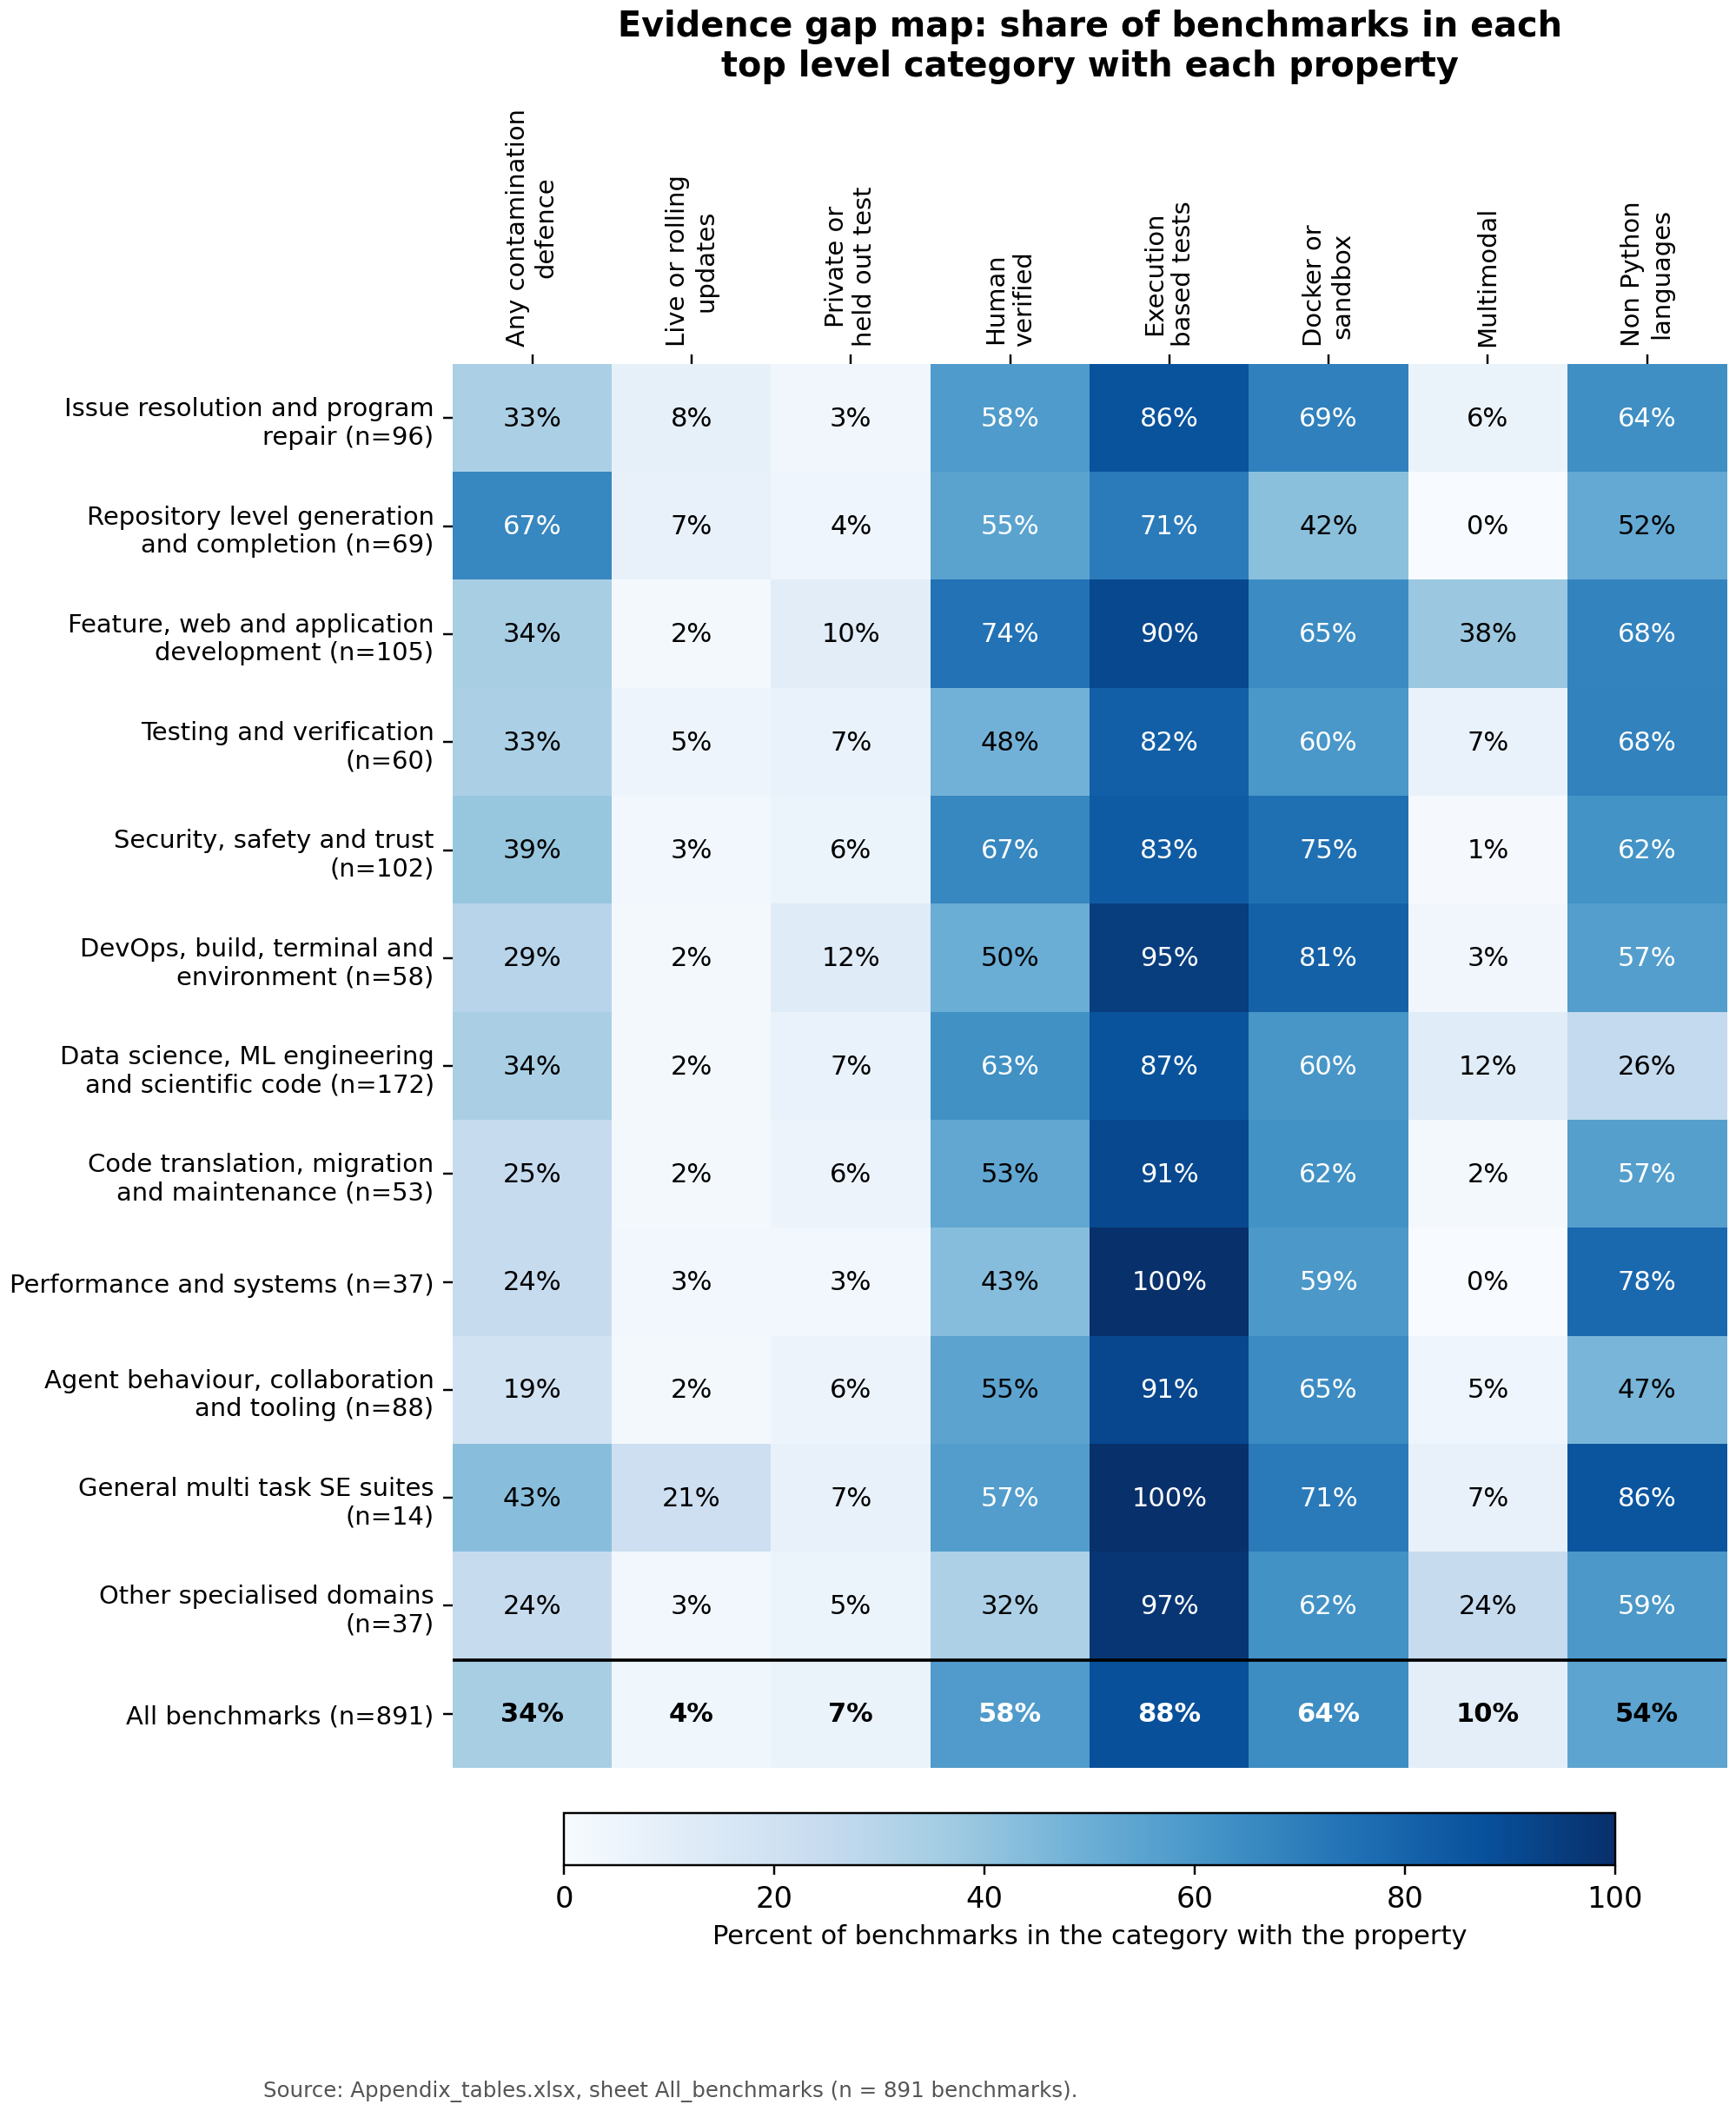

In [10]:
COLS = [('any_contamination_defence', 'Any contamination\ndefence'), ('live_updates', 'Live or rolling\nupdates'), ('private_test_set', 'Private or\nheld out test'),
        ('human_verified', 'Human\nverified'), ('execution_based_tests', 'Execution\nbased tests'), ('docker_or_sandbox', 'Docker or\nsandbox'),
        ('multimodal', 'Multimodal'), ('non_python_languages', 'Non Python\nlanguages')]
mat, GAP = [], {}
for t in TOPS + ['All benchmarks']:
    bs = B if t == 'All benchmarks' else [b for b in B if b['Top level category'] == t]
    row = [100.0 * sum(b['flags'][k] for b in bs) / len(bs) for k, _ in COLS]; mat.append(row)
    GAP[t] = {'n': len(bs), **{k: round(v, 1) for (k, _), v in zip(COLS, row)}}
rlabs = ['\n'.join(textwrap.wrap('%s (n=%d)' % (t, GAP[t]['n']), 30)) for t in TOPS] + ['All benchmarks (n=%d)' % N]
fig, ax = plt.subplots(figsize=(8.6, 10.2)); im = ax.imshow(mat, cmap='Blues', vmin=0, vmax=100, aspect='auto')
for i, row in enumerate(mat):
    for j, v in enumerate(row):
        ax.text(j, i, '%.0f%%' % v, ha='center', va='center', fontsize=10, color='white' if v > 55 else 'black', fontweight='bold' if i == len(mat) - 1 else 'normal')
ax.axhline(len(TOPS) - 0.5, color='black', lw=1.2)
ax.set_xticks(range(len(COLS))); ax.set_xticklabels([c for _, c in COLS], fontsize=9.5, rotation=90, va='bottom', ha='center')
ax.set_yticks(range(len(rlabs))); ax.set_yticklabels(rlabs, fontsize=9.5); ax.xaxis.tick_top()
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, orientation='horizontal', fraction=0.035, pad=0.03); cb.set_label('Percent of benchmarks in the category with the property', fontsize=10)
ax.set_title('Evidence gap map: share of benchmarks in each\ntop level category with each property', pad=12, fontsize=13)
note(fig, 0.0); save(fig, 'Figure_9_evidence_gap_map')
print('all benchmarks, percent with each property:', {k: v for k, v in GAP['All benchmarks'].items()})
display(Image(str(FIG / 'Figure_9_evidence_gap_map.png'), width=600))

## 5.4 Tables

Each table is written as an Excel file with a title row, a source note and a header row.

In [11]:
def write_xlsx(name, header, rows, title, note_, widths=None):
    wb = openpyxl.Workbook(); ws = wb.active; ws.title = name[:31]
    ws.append([title]); ws['A1'].font = Font(bold=True, size=12)
    ws.append([note_]); ws['A2'].font = Font(italic=True, size=9, color='555555')
    ws.append(header)
    for c in ws[3]: c.font = Font(bold=True, color='FFFFFF'); c.fill = PatternFill('solid', fgColor='332288'); c.alignment = Alignment(wrap_text=True, vertical='top')
    for r in rows: ws.append(r)
    for row in ws.iter_rows(min_row=4):
        for c in row: c.alignment = Alignment(wrap_text=True, vertical='top')
    for i, h in enumerate(header, 1): ws.column_dimensions[get_column_letter(i)].width = widths[i - 1] if widths else max(12, min(50, len(str(h)) + 4))
    ws.freeze_panes = 'A4'; ws.auto_filter.ref = 'A3:%s%d' % (get_column_letter(len(header)), ws.max_row)
    wb.save(TAB / (name + '.xlsx')); MADE.append('Tables/' + name + '.xlsx'); return rows
NOTE = f'Made from Appendix_tables.xlsx (sheet All_benchmarks, n = {N} benchmarks) by Step_5_Analysis_tables_and_figures.ipynb.'

# Table 1. Earlier surveys compared with this review
h1 = [k for k in SURV[0]]
t1 = [[r.get(k) for k in h1] for r in SURV]
check('the "This review" row of the related surveys counts every benchmark', next(r for r in SURV if r.get('Survey (record ID)') == 'This review')['Benchmarks covered'] == N)
write_xlsx('Related_surveys', h1, t1, 'Earlier surveys compared with this review',
           'Made from Appendix_tables.xlsx (sheet Related_surveys). Y = dedicated analysis or section; P = partial or in passing; N = not found in the text; NS = not stated in the abstract.',
           [5, 26, 7, 30, 30, 22, 18, 12, 14, 14, 18, 12, 50])

# Classification scheme: facets, values, definitions and counts
t4 = []
for k, fname in [('Top level category', 'F2 Task category, top level (RQ2)'), ('Granularity', 'F2 Granularity (RQ2)'), ('Modality', 'F2 Modality (RQ2)'),
                 ('Evaluates', 'F1 Evaluation target (RQ1)'), ('Contamination defence (strict)', 'F3 Contamination defence (RQ3)'), ('Task source', 'F4 Task source (RQ4)'),
                 ('Test source', 'F4 Test source (RQ4)'), ('Validation', 'F4 Validation (RQ4)'), ('Environment', 'F4 Environment (RQ4)'), ('Limitations', 'F5 Limitation types (RQ5)')]:
    multi = k in MULTI; c = collections.Counter(x for b in B for x in (b[k] if multi else [b[k]])); ce = collections.Counter(x for b in EVAL for x in (b[k] if multi else [b[k]]))
    order = TOPS if k == 'Top level category' else [v for v, _ in c.most_common()]
    d = TOPDEF if k == 'Top level category' else DEFS[k]
    for v in order: t4.append([fname + (' (multi valued)' if multi else ''), v, d.get(v, ''), c[v], round(100.0 * c[v] / N, 1), ce[v], round(100.0 * ce[v] / len(EVAL), 1)])
for top in TOPS:
    for t in sorted([t for t in TAXO if t['Top level category'] == top], key=lambda t: -int(t[CNT])):
        _e = sum(1 for b in EVAL if b['Sub category'] == t['Sub category'] and b['Top level category'] == top)
        t4.append(['F2 Task sub category (RQ2), under ' + top, t['Sub category'], t['Description'], int(t[CNT]), round(100.0 * int(t[CNT]) / N, 1), _e, round(100.0 * _e / len(EVAL), 1)])
write_xlsx('Classification_scheme', ['Facet', 'Value', 'Definition', 'All benchmarks (n)', 'Percent of %d' % N, 'Evaluation benchmarks (n)', 'Percent of %d' % len(EVAL)], t4,
           'Classification scheme: facets, values, definitions and counts', NOTE + ' Counts are given for all benchmarks and for the evaluation benchmarks (the base of Tables 5, 6, 8 and 9 of the report). Multi valued facets can sum to more than 100 percent.', [38, 40, 70, 12, 10, 12, 10])

# Main benchmark table, sorted by category, sub category, year and name
SUBORD = [t['Sub category'] for top in TOPS for t in sorted([t for t in TAXO if t['Top level category'] == top], key=lambda t: -int(t[CNT]))]
h5 = ['ID', 'Benchmark', 'Year', 'Role', 'Top category', 'Sub category', 'Contamination defence', 'Task source', 'Test source', 'Environment',
      'Main limitation', 'Quality score (0 to 6)', 'Evidence level']
t5 = [[b['ID'], b['Benchmark'], b['Year'], b['Role'], b['Top level category'], b['Sub category'], '; '.join(b['Contamination defence (strict)']),
       '; '.join(b['Task source']), '; '.join(b['Test source']), b['Environment'], b['Main limitation'] or '', b['Quality score (0 to 6)'], b['Evidence level']]
      for b in sorted(B, key=lambda b: (TOPS.index(b['Top level category']), SUBORD.index(b['Sub category']), b['Year'], b['Benchmark'].lower()))]
qs = collections.Counter(int(b['Quality score (0 to 6)']) for b in B)
write_xlsx('Main_benchmark_table', h5, t5, f'Main benchmark table ({N} benchmarks, sorted by category then year)',
           NOTE + ' Quality score: sum of six yes or no items. Distribution: ' + ', '.join(f'score {k}: {qs[k]}' for k in sorted(qs)) +
           f'. Mean {sum(int(b["Quality score (0 to 6)"]) for b in B) / N:.2f}.', [8, 30, 7, 18, 30, 30, 30, 24, 24, 16, 60, 10, 12])

# Contamination defences per top level category: the evaluation benchmarks, in the order and with the columns of Table 7 of the report
PREVD = {'Live or rolling updates', 'Private or held out test set', 'Time cutoff', 'Task rewriting or mutation', 'New or synthetic tasks (contamination motivated)', 'Other training exposure reduction'}
DETD = {'Decontamination or memorisation check', 'Canary strings'}; LASTD = {'Live or rolling updates', 'Private or held out test set'}
DV = [v for v, _ in collections.Counter(x for b in EVAL for x in b['Contamination defence (strict)']).most_common() if v != 'None reported'] + ['None reported']
h7 = ['Top category', 'n', 'Any defence (n)', 'Any defence (%)', 'Prevention (n)', 'Detection (n)', 'Lasting (n)'] + [x for v in DV for x in (v + ' (n)', v + ' (%)')]
t7 = []
for t in TOPS + ['All evaluation benchmarks']:
    bs = EVAL if t == 'All evaluation benchmarks' else [b for b in EVAL if b['Top level category'] == t]; n = len(bs)
    s_ = [set(b['Contamination defence (strict)']) for b in bs]
    anyd = sum(b['flags']['any_contamination_defence'] for b in bs); cs = [sum(v in x for x in s_) for v in DV]
    t7.append([t, n, anyd, round(100.0 * anyd / n, 1), sum(1 for x in s_ if x & PREVD), sum(1 for x in s_ if x & DETD), sum(1 for x in s_ if x & LASTD)]
              + [x for c in cs for x in (c, round(100.0 * c / n, 1))])
t7 = sorted(t7[:-1], key=lambda r: (-r[3], TOPS.index(r[0]))) + t7[-1:]
write_xlsx('Contamination_by_category', h7, t7, 'Evaluation benchmarks with any strict contamination defence, by top level category (Table 7 of the report)',
           NOTE + f' Counts cover the {len(EVAL)} evaluation benchmarks. Prevention, detection and lasting (live updates or private sets) count benchmarks with at least one defence of that kind. A benchmark can use several defences.', [44, 6, 10, 10, 10, 10, 10] + [12] * (2 * len(DV)))

# The 30 benchmarks named in the most full texts
top = sorted(B, key=lambda b: (-int(b['Documents mentioning'] or 0), -int(b['OpenAlex citations'] or 0), b['Benchmark'].lower()))[:30]   # ties: more citations first
t30 = [[i + 1, b['Benchmark'], b['Role'], int(b['Documents mentioning'] or 0), int(b['Agent or method papers mentioning'] or 0), b['OpenAlex citations']]
       for i, b in enumerate(top)]
write_xlsx('Most_mentioned_benchmarks_top30', ['Rank', 'Benchmark', 'Role', 'Documents mentioning', 'Of which agent or method papers', 'OpenAlex citations'], t30,
           'Benchmarks most often named in the full texts (top 30)',
           'Made from Appendix_tables.xlsx (sheet All_benchmarks). Documents mentioning: full texts whose body text names the benchmark, excluding its own papers. '
           'OpenAlex citations: highest count over the benchmark\'s own records (empty for seed variants without their own paper).', [6, 32, 30, 14, 16, 14])
for name in ['Contamination_by_category']:
    print(name); [print('  ', r[0], '| n', r[1], '| any defence', r[2], f'({r[3]}%)') for r in t7]

PASS the "This review" row of the related surveys counts every benchmark


Contamination_by_category
   Repository level generation and completion | n 69 | any defence 46 (66.7%)
   General multi task SE suites | n 14 | any defence 6 (42.9%)
   Security, safety and trust | n 102 | any defence 40 (39.2%)
   Issue resolution and program repair | n 87 | any defence 31 (35.6%)
   Feature, web and application development | n 105 | any defence 36 (34.3%)
   Data science, ML engineering and scientific code | n 170 | any defence 58 (34.1%)
   Testing and verification | n 60 | any defence 20 (33.3%)
   DevOps, build, terminal and environment | n 57 | any defence 17 (29.8%)
   Code translation, migration and maintenance | n 53 | any defence 13 (24.5%)
   Performance and systems | n 37 | any defence 9 (24.3%)
   Other specialised domains | n 37 | any defence 9 (24.3%)
   Agent behaviour, collaboration and tooling | n 88 | any defence 17 (19.3%)
   All evaluation benchmarks | n 879 | any defence 302 (34.4%)


## 5.5 Summary of the main numbers

In [12]:
E = len(EVAL)
pct = lambda c, n: f'{c} ({100 * c / n:.1f} percent)'
ev = lambda f: sum(f(b) for b in EVAL)
print('Records identified:', f_(P('Records identified')), '| reports assessed on full text:', f_(P('Reports assessed on their full text')),
      '| reports included:', f_(P('Reports included')), '| not retrieved (EXC8):', P('Reports not retrieved, no open access full text (EXC8)'))
print('Unique benchmarks:', N, f'({E} evaluation benchmarks, {N - E} training resources) | taxonomy: {len(TOPS)} top level, {len(TAXO)} sub categories')
print('Evaluation benchmarks with no strict contamination defence:', pct(ev(lambda b: not b['flags']['any_contamination_defence']), E))
print('Evaluation benchmarks with live updates or a private test set:', pct(ev(lambda b: b['flags']['live_updates'] or b['flags']['private_test_set']), E))
print('All benchmarks with any strict defence:', pct(sum(b['flags']['any_contamination_defence'] for b in B), N))
for k, v in [('Task source', 'Open source repositories'), ('Task source', 'Human written'), ('Task source', 'LLM generated'),
             ('Limitations', 'Scope limits'), ('Limitations', 'Evaluation noise'), ('Limitations', 'Repository or language dependence'), ('Limitations', 'Contamination risk')]:
    print(f'{k}: {v}:', pct(ev(lambda b: v in b[k]), E))
print('Docker or sandbox:', pct(ev(lambda b: b['flags']['docker_or_sandbox']), E))
print('Top 10 by documents mentioning:', ', '.join(f'{r[1]} {r[3]}' for r in t30[:10]))
print('\nfiles written:'); [print('  ', m) for m in MADE]
failed = [w for w, ok in CHECKS if not ok]
print(f'\n{len(CHECKS) - len(failed)} of {len(CHECKS)} checks pass' + ('' if not failed else ': FAILED ' + '; '.join(failed)))

Records identified: 28,426 | reports assessed on full text: 1,454 | reports included: 1,010 | not retrieved (EXC8): 382
Unique benchmarks: 891 (879 evaluation benchmarks, 12 training resources) | taxonomy: 12 top level, 45 sub categories
Evaluation benchmarks with no strict contamination defence: 577 (65.6 percent)
Evaluation benchmarks with live updates or a private test set: 89 (10.1 percent)
All benchmarks with any strict defence: 303 (34.0 percent)
Task source: Open source repositories: 331 (37.7 percent)
Task source: Human written: 313 (35.6 percent)
Task source: LLM generated: 214 (24.3 percent)
Limitations: Scope limits: 498 (56.7 percent)
Limitations: Evaluation noise: 303 (34.5 percent)
Limitations: Repository or language dependence: 244 (27.8 percent)
Limitations: Contamination risk: 168 (19.1 percent)
Docker or sandbox: 562 (63.9 percent)
Top 10 by documents mentioning: SWE-bench 801, SWE-bench Verified 283, Terminal-Bench 2.0 208, SWE-Bench Pro 138, MLE-bench 125, RepoBench